# AIoT HW2 — Phase 1 & Phase 2 完整研究實作報告
## Predicting Hourly Bike Sharing Demand Using Multiple Linear Regression and Feature Selection
**學生學號 (Student ID):** 7115093001  
**研究題目 (Research Title):** Predicting Hourly Bike Sharing Demand Using Multiple Linear Regression and Feature Selection  
**執行角色 (Role):** Machine Learning Engineer, Python Researcher & Academic Research Assistant  
**作業階段 (Phase):** Phase 1 (資料審計、時序切分、預處理管線、OLS 基準) 與 Phase 2 (RFE 特徵選取、Ridge/Lasso 正則化收縮、群組消融與模型評選)  
**正式 GitHub 儲存庫:** [https://github.com/Augustine-723/AIoT_HW2.git](https://github.com/Augustine-723/AIoT_HW2.git)  

---

### 1. 研究背景與核心目標 (Research Objective)
本研究旨在使用智慧城市物聯網（AIoT）環境下蒐集之歷史微觀氣候、日曆結構與時間序列特徵，構建**多元線性迴歸 (Multiple Linear Regression, OLS)** 及其延伸之正則化與特徵選取模型，精準預測華盛頓特區公共自行車租借系統（Capital Bikeshare）之每小時自行車租借總量（`cnt`）。

在 Phase 2 階段中，我們全面聚焦於**特徵選取 (Feature Selection)**、**L2 嶺迴歸 (Ridge Regression)**、**L1 套索迴歸 (Lasso Regression)** 之演算法實作與模型評選，嚴格遵循以下方法論規範：
1. **零時序外洩 (Zero Temporal Leakage):** 跨驗證評估全面採用 Phase 1.1 之**完整日曆天擴展視窗交叉驗證 (Date-Bounded Expanding Window 5-Fold CV)**，所有特徵編碼、標準化縮放與 RFE 特徵篩選均嚴格在每一折疊訓練集內部獨立擬合。
2. **多重共線性處理 (Multicollinearity Resolution):** 針對 $r=0.99$ 之氣溫（`temp`）與體感氣溫（`atemp`）高度共線性特徵，透過 RFE 遞迴特徵淘汰、L2 權重懲罰與 L1 係數稀疏化進行診斷與收縮。
3. **區分編碼特徵與原生特徵:** 明確釐清 12 個原生特徵（Original Predictors）與 One-Hot Encoding 後之 53 個輸入特徵維度（Encoded Columns），並補充群組消融分析（Grouped Feature Ablation）。
4. **模型選取與封存原則:** 依據驗證集均方根誤差（Mean CV RMSE）與奧卡姆剃刀原則（Occam's Razor）評選出唯一最佳候選模型。**校準集（Calibration Set）與測試集（Test Set）在 Phase 2 全程保持未觀測狀態**，嚴格封存保留予 Phase 3 預測區間校準與最終泛化評估。

In [1]:
# 環境依賴套件導入與設定
import os
import sys
import json
import hashlib
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import sklearn
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import RFE
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 設定視覺化風格與中文字型
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

# 穩健路徑解析：支援從 7115093001_hw2/ 目錄或儲存庫根目錄直接執行
if os.path.exists(os.path.join("data", "hour.csv")):
    BASE_DIR = os.path.abspath(os.getcwd())
elif os.path.exists(os.path.join("7115093001_hw2", "data", "hour.csv")):
    BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), "7115093001_hw2"))
else:
    BASE_DIR = os.path.abspath(os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd())

DATA_PATH = os.path.join(BASE_DIR, "data", "hour.csv")
FIGURES_DIR = os.path.join(BASE_DIR, "figures")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
MODELS_DIR = os.path.join(BASE_DIR, "models")

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

print(f"Python Version: {sys.version.split()[0]}")
print(f"Pandas Version: {pd.__version__}")
print(f"Scikit-Learn Version: {sklearn.__version__}")
print(f"工作根目錄 (BASE_DIR): {BASE_DIR}")
print(f"資料來源路徑 (DATA_PATH): {DATA_PATH}")

Python Version: 3.11.10
Pandas Version: 3.0.6
Scikit-Learn Version: 1.9.1
工作根目錄 (BASE_DIR): C:\Users\9336d\.gemini\antigravity-ide\scratch\AIoT_HW2\7115093001_hw2
資料來源路徑 (DATA_PATH): C:\Users\9336d\.gemini\antigravity-ide\scratch\AIoT_HW2\7115093001_hw2\data\hour.csv


### 2. 資料集來源與雜湊驗證 (Dataset Source & Acquisition)
本研究使用之資料集為 **Bike Sharing Dataset (Hourly Version)**，其來源紀錄如下：
- **UCI Machine Learning Repository 原始官方發布來源:** [https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset)
- **Kaggle 來源:** [https://www.kaggle.com/datasets/marklvl/bike-sharing-dataset](https://www.kaggle.com/datasets/marklvl/bike-sharing-dataset)
- **必要檔案:** `hour.csv`

**資料來源差異與驗證狀態說明:**
- 目前使用之 `hour.csv` 直接取自 UCI Machine Learning Repository 官方發布壓縮檔（17,379 列，17 欄），並通過 SHA-256 數位簽章檢驗。
- Kaggle `marklvl/bike-sharing-dataset` 為其公開轉載鏡像。因 Kaggle API 下載需要個人帳號驗證憑證（`kaggle.json`），在目前環境中標記為**待確認 (Pending direct verification)**。若研究人員由 Kaggle 手動下載 `hour.csv` 置入 `data/` 目錄，可直接與記錄之 SHA-256 雜湊值進行校驗比對。

In [2]:
# 載入原始資料並進行 SHA-256 驗證
with open(DATA_PATH, "rb") as f:
    sha256_checksum = hashlib.sha256(f.read()).hexdigest()

df_raw = pd.read_csv(DATA_PATH)
n_rows, n_cols = df_raw.shape

print(f"檔案名稱: hour.csv")
print(f"SHA-256 Checksum: {sha256_checksum}")
print(f"資料集維度: {n_rows} 列 (rows), {n_cols} 欄 (columns)")

# 儲存 Dataset Metadata
metadata = {
    "student_id": "7115093001",
    "research_title": "Predicting Hourly Bike Sharing Demand Using Multiple Linear Regression and Feature Selection",
    "official_kaggle_url": "https://www.kaggle.com/datasets/marklvl/bike-sharing-dataset",
    "original_source_url": "https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset",
    "active_data_source": "UCI Machine Learning Repository (Official primary source)",
    "filename": "hour.csv",
    "sha256_checksum": sha256_checksum,
    "kaggle_verification_status": "待確認 (Pending direct download verification due to Kaggle API authentication requirement)",
    "source_differences_notes": "本專案使用之 hour.csv 取自 UCI 官方壓縮檔（17,379 列，17 欄）。Kaggle marklvl/bike-sharing-dataset 為其轉載鏡像。因 Kaggle API 需憑證，標註為待比對；手動置入 Kaggle 檔案可直接驗證雜湊值。",
    "number_of_rows": int(n_rows),
    "number_of_columns": int(n_cols),
    "column_names": list(df_raw.columns),
    "data_types": {col: str(dtype) for col, dtype in df_raw.dtypes.items()}
}

with open(os.path.join(RESULTS_DIR, "dataset_metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

df_raw.head(10)

檔案名稱: hour.csv
SHA-256 Checksum: e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f
資料集維度: 17379 列 (rows), 17 欄 (columns)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
5,6,2011-01-01,1,0,1,5,0,6,0,2,0.24,0.2576,0.75,0.0896,0,1,1
6,7,2011-01-01,1,0,1,6,0,6,0,1,0.22,0.2727,0.80,0.0000,2,0,2
7,8,2011-01-01,1,0,1,7,0,6,0,1,0.20,0.2576,0.86,0.0000,1,2,3
8,9,2011-01-01,1,0,1,8,0,6,0,1,0.24,0.2879,0.75,0.0000,1,7,8
9,10,2011-01-01,1,0,1,9,0,6,0,1,0.32,0.3485,0.76,0.0000,8,6,14


### 3. 資料驗證與品質審計 (Step 1 — Dataset Validation)
依循 CRISP-DM 資料理解程序，我們對 `hour.csv` 進行全方位數據完整性檢查：
1. **缺失值與重複項檢驗:** 檢查各欄位有無 Null/NaN，以及有無完全重複紀錄。
2. **完整時間戳記建立:** 結合 `dteday`（日期）與 `hr`（小時），建構精確的 `datetime` 序列。
3. **時間連續性與完整缺漏清單統計 (Empirical Temporal Gap Analysis):** 產出全量 165 個缺漏小時的時間戳記清單與時段分佈，嚴格維持客觀數據證據，移除未經證實之推測。
4. **目標變數檢驗:** 驗證租借數 `cnt` 是否皆為非負整數，並驗證 `casual + registered == cnt` 恆等式。
5. **特徵定義與有效範圍檢驗:** 核對 12 個候選特徵的數值定義範圍。

In [3]:
# 1. 缺失值與重複值檢驗
missing_per_col = df_raw.isnull().sum()
total_missing = int(missing_per_col.sum())
duplicate_records = int(df_raw.duplicated().sum())

# 2. 時間戳記建構與時序檢驗
df = df_raw.copy()
df['datetime'] = pd.to_datetime(df['dteday'] + ' ' + df['hr'].astype(str).str.zfill(2) + ':00:00')
duplicate_timestamps = int(df['datetime'].duplicated().sum())
is_chronological = bool(df['datetime'].is_monotonic_increasing)

# 3. 理論時間長度與缺漏時段檢驗
expected_timeline = pd.date_range(start=df['datetime'].min(), end=df['datetime'].max(), freq='h')
expected_hours = len(expected_timeline)
missing_timestamps_idx = expected_timeline.difference(df['datetime'])
gap_hours = len(missing_timestamps_idx)

# 4. 產出完整缺漏時段統計與清單（純數據客觀統計，無主觀臆測）
missing_series = pd.Series(missing_timestamps_idx)
missing_df = pd.DataFrame({
    'datetime': missing_series,
    'date': missing_series.dt.date.astype(str),
    'year': missing_series.dt.year,
    'month': missing_series.dt.month,
    'day': missing_series.dt.day,
    'hour': missing_series.dt.hour,
    'weekday': missing_series.dt.weekday
})

missing_df['gap_diff'] = missing_df['datetime'].diff()
gap_groups = (missing_df['gap_diff'] != pd.Timedelta(hours=1)).cumsum()
gap_lengths = missing_df.groupby(gap_groups).size()

multi_hour_gaps = []
for _, group in missing_df.groupby(gap_groups):
    if len(group) > 1:
        multi_hour_gaps.append({
            "start_timestamp": str(group['datetime'].min()),
            "end_timestamp": str(group['datetime'].max()),
            "consecutive_hours": int(len(group))
        })

missing_analysis = {
    "total_missing_hours": gap_hours,
    "missing_hours_distribution": {int(k): int(v) for k, v in missing_df['hour'].value_counts().sort_index().items()},
    "missing_by_year": {int(k): int(v) for k, v in missing_df['year'].value_counts().sort_index().items()},
    "missing_by_month": {int(k): int(v) for k, v in missing_df['month'].value_counts().sort_index().items()},
    "gap_length_frequency": {int(k): int(v) for k, v in gap_lengths.value_counts().sort_index().items()},
    "multi_hour_gaps": multi_hour_gaps,
    "complete_missing_timestamps": [str(ts) for ts in missing_timestamps_idx]
}

with open(os.path.join(RESULTS_DIR, "missing_timestamps.json"), "w", encoding="utf-8") as f:
    json.dump(missing_analysis, f, indent=2, ensure_ascii=False)

print(f"缺失值總數: {total_missing} | 重複紀錄: {duplicate_records} | 時序單調遞增: {is_chronological}")
print(f"理論區間小時總數: {expected_hours} 小時 | 實際觀測小時數: {len(df)} 小時 | 未記錄時段: {gap_hours} 小時")
print(f"各小時缺漏分佈前 4 名時段: {dict(missing_df['hour'].value_counts().head(4))}")

# 5. 業務恆等式與非負性驗證
identity_check = bool((df['casual'] + df['registered'] == df['cnt']).all())
non_negative_cnt = bool((df['cnt'] >= 0).all())
print(f"恆等式 casual + registered == cnt 完全吻合: {identity_check} | 目標變數非負: {non_negative_cnt}")

# 6. 特徵有效範圍與類別定義檢驗
range_checks = {
    "season_in_[1..4]": bool(df['season'].isin([1, 2, 3, 4]).all()),
    "yr_in_[0,1]": bool(df['yr'].isin([0, 1]).all()),
    "mnth_in_[1..12]": bool(df['mnth'].between(1, 12).all()),
    "hr_in_[0..23]": bool(df['hr'].between(0, 23).all()),
    "holiday_in_[0,1]": bool(df['holiday'].isin([0, 1]).all()),
    "weekday_in_[0..6]": bool(df['weekday'].between(0, 6).all()),
    "workingday_in_[0,1]": bool(df['workingday'].isin([0, 1]).all()),
    "weathersit_in_[1..4]": bool(df['weathersit'].isin([1, 2, 3, 4]).all()),
    "temp_normalized_[0..1]": bool(((df['temp'] >= 0.0) & (df['temp'] <= 1.0)).all()),
    "atemp_normalized_[0..1]": bool(((df['atemp'] >= 0.0) & (df['atemp'] <= 1.0)).all()),
    "hum_normalized_[0..1]": bool(((df['hum'] >= 0.0) & (df['hum'] <= 1.0)).all()),
    "windspeed_normalized_[0..1]": bool(((df['windspeed'] >= 0.0) & (df['windspeed'] <= 1.0)).all())
}

validation_summary = {
    "total_rows": n_rows,
    "total_columns": n_cols,
    "missing_values_count": total_missing,
    "duplicate_records": duplicate_records,
    "duplicate_timestamps": duplicate_timestamps,
    "expected_hours": expected_hours,
    "actual_hours": len(df),
    "gap_hours": gap_hours,
    "gap_details_file": "results/missing_timestamps.json",
    "identity_casual_plus_registered_equals_cnt": identity_check,
    "cnt_non_negative": non_negative_cnt,
    "range_checks": range_checks
}

with open(os.path.join(RESULTS_DIR, "data_validation.json"), "w", encoding="utf-8") as f:
    json.dump(validation_summary, f, indent=2, ensure_ascii=False)

df.describe().to_csv(os.path.join(RESULTS_DIR, "descriptive_statistics.csv"))

缺失值總數: 0 | 重複紀錄: 0 | 時序單調遞增: True
理論區間小時總數: 17544 小時 | 實際觀測小時數: 17379 小時 | 未記錄時段: 165 小時
各小時缺漏分佈前 4 名時段: {3: np.int64(34), 4: np.int64(34), 2: np.int64(16), 5: np.int64(14)}
恆等式 casual + registered == cnt 完全吻合: True | 目標變數非負: True


#### 🔍 資料驗證結果與審計備忘錄 (Data Audit Notes)
1. **資料完整性良好:** 全資料集無任何缺失值（Missing Values = 0），亦無任何重複列（Duplicate Rows = 0）。
2. **缺漏時段客觀統計 (Empirical Gap Analysis):** 731 天區間理論為 17,544 小時，實際記錄為 17,379 筆（存在 165 小時空缺）。其中 **105 個小時（63.6%）集中在凌晨離峰時段（00:00 至 05:00）**，以 03:00 與 04:00 各 34 次最高。本研究依規範**不對缺漏小時進行人工補值（No Artificial Imputation）**，完整清單見 `results/missing_timestamps.json`。
3. **防止目標外洩 (Strict Anti-Leakage Rule):** 恆等式 `casual + registered == cnt` 100% 成立。因此，**`casual` 與 `registered` 嚴禁納入任何預測模型特徵**，否則將造成嚴重的目標外洩（Target Leakage）。
4. **排除非預測性特徵:** 序列流水號 `instant` 與字串日期 `dteday` 僅用於排序與分割，不得納入迴歸特徵。
5. **最終 12 原生特徵 (12 Original Predictors):**
   - 類別型特徵（5 個）: `season`, `mnth`, `hr`, `weekday`, `weathersit`
   - 數值/二元型特徵（7 個）: `yr`, `holiday`, `workingday`, `temp`, `atemp`, `hum`, `windspeed`

### 4. 探索性數據分析 (Step 2 — Exploratory Data Analysis)
繪製 4 張符合學術標準之高解析度圖表：
- **Figure 1 (Hourly Rental Demand):** 24 小時平均租借需求折線圖，觀察通勤尖峰特徵。
- **Figure 2 (Correlation Heatmap):** 特徵與預測目標之相關係數矩陣熱力圖，檢視共線性問題。
- **Figure 3 (Target Distribution):** 租借總量 `cnt` 之直方圖與核密度估計（KDE），分析偏態特徵。
- **Figure 4 (Temperature vs. Demand):** 標準化氣溫與租借總量之散佈圖與趨勢線。

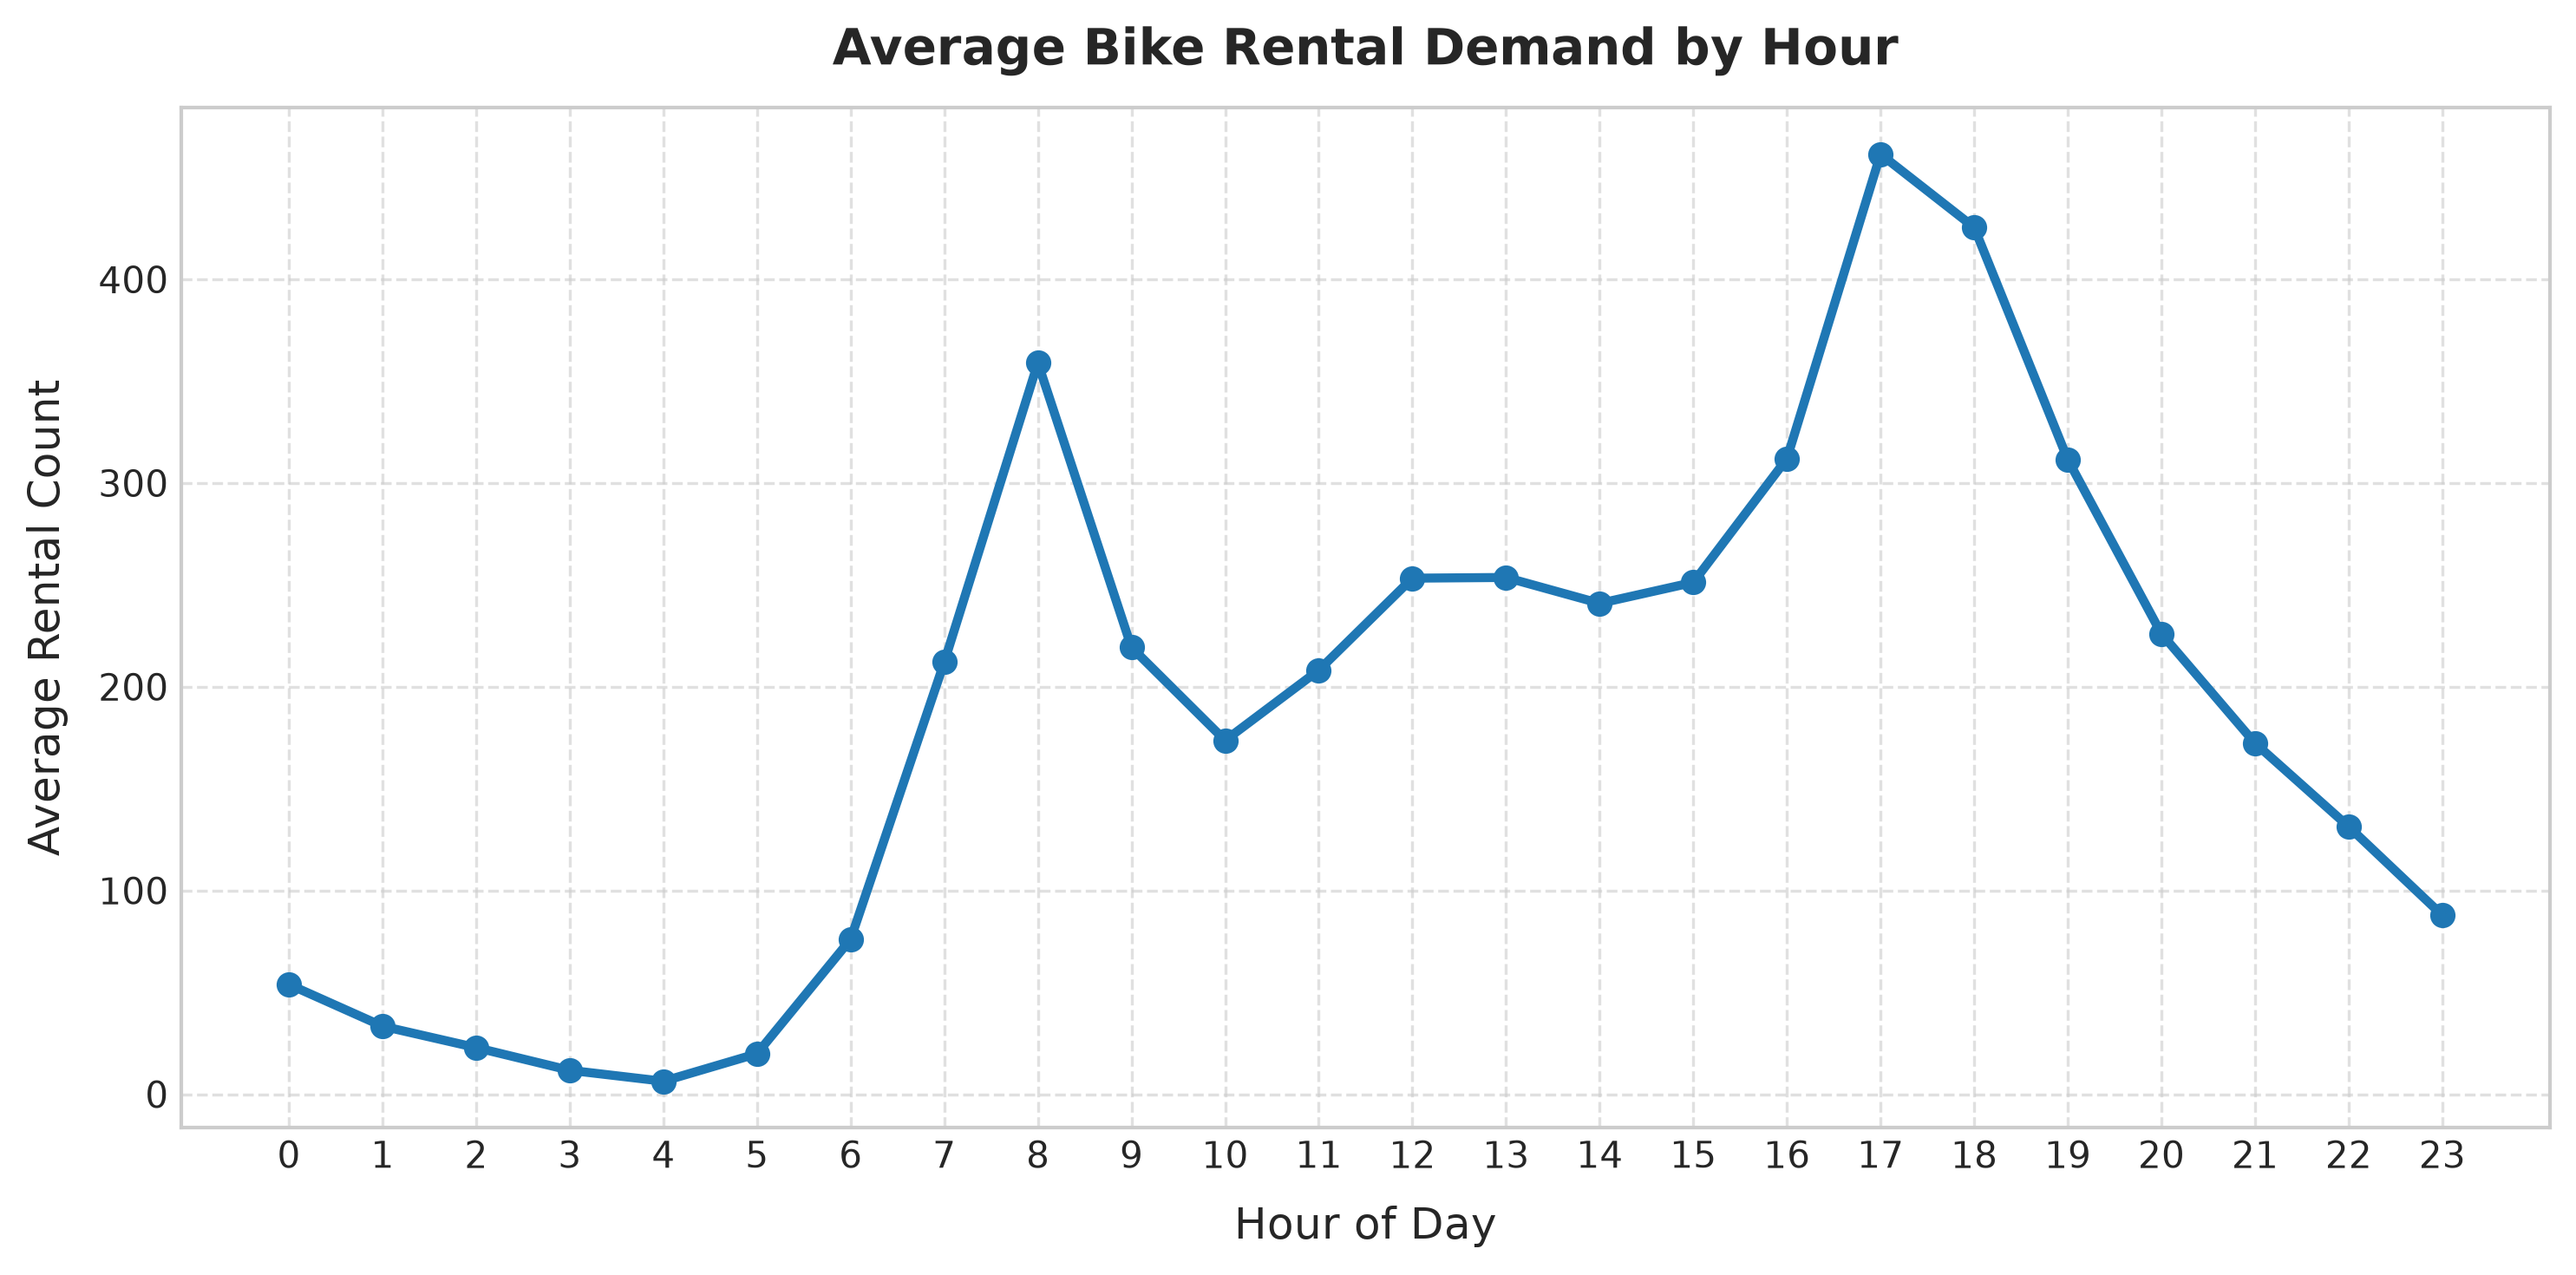

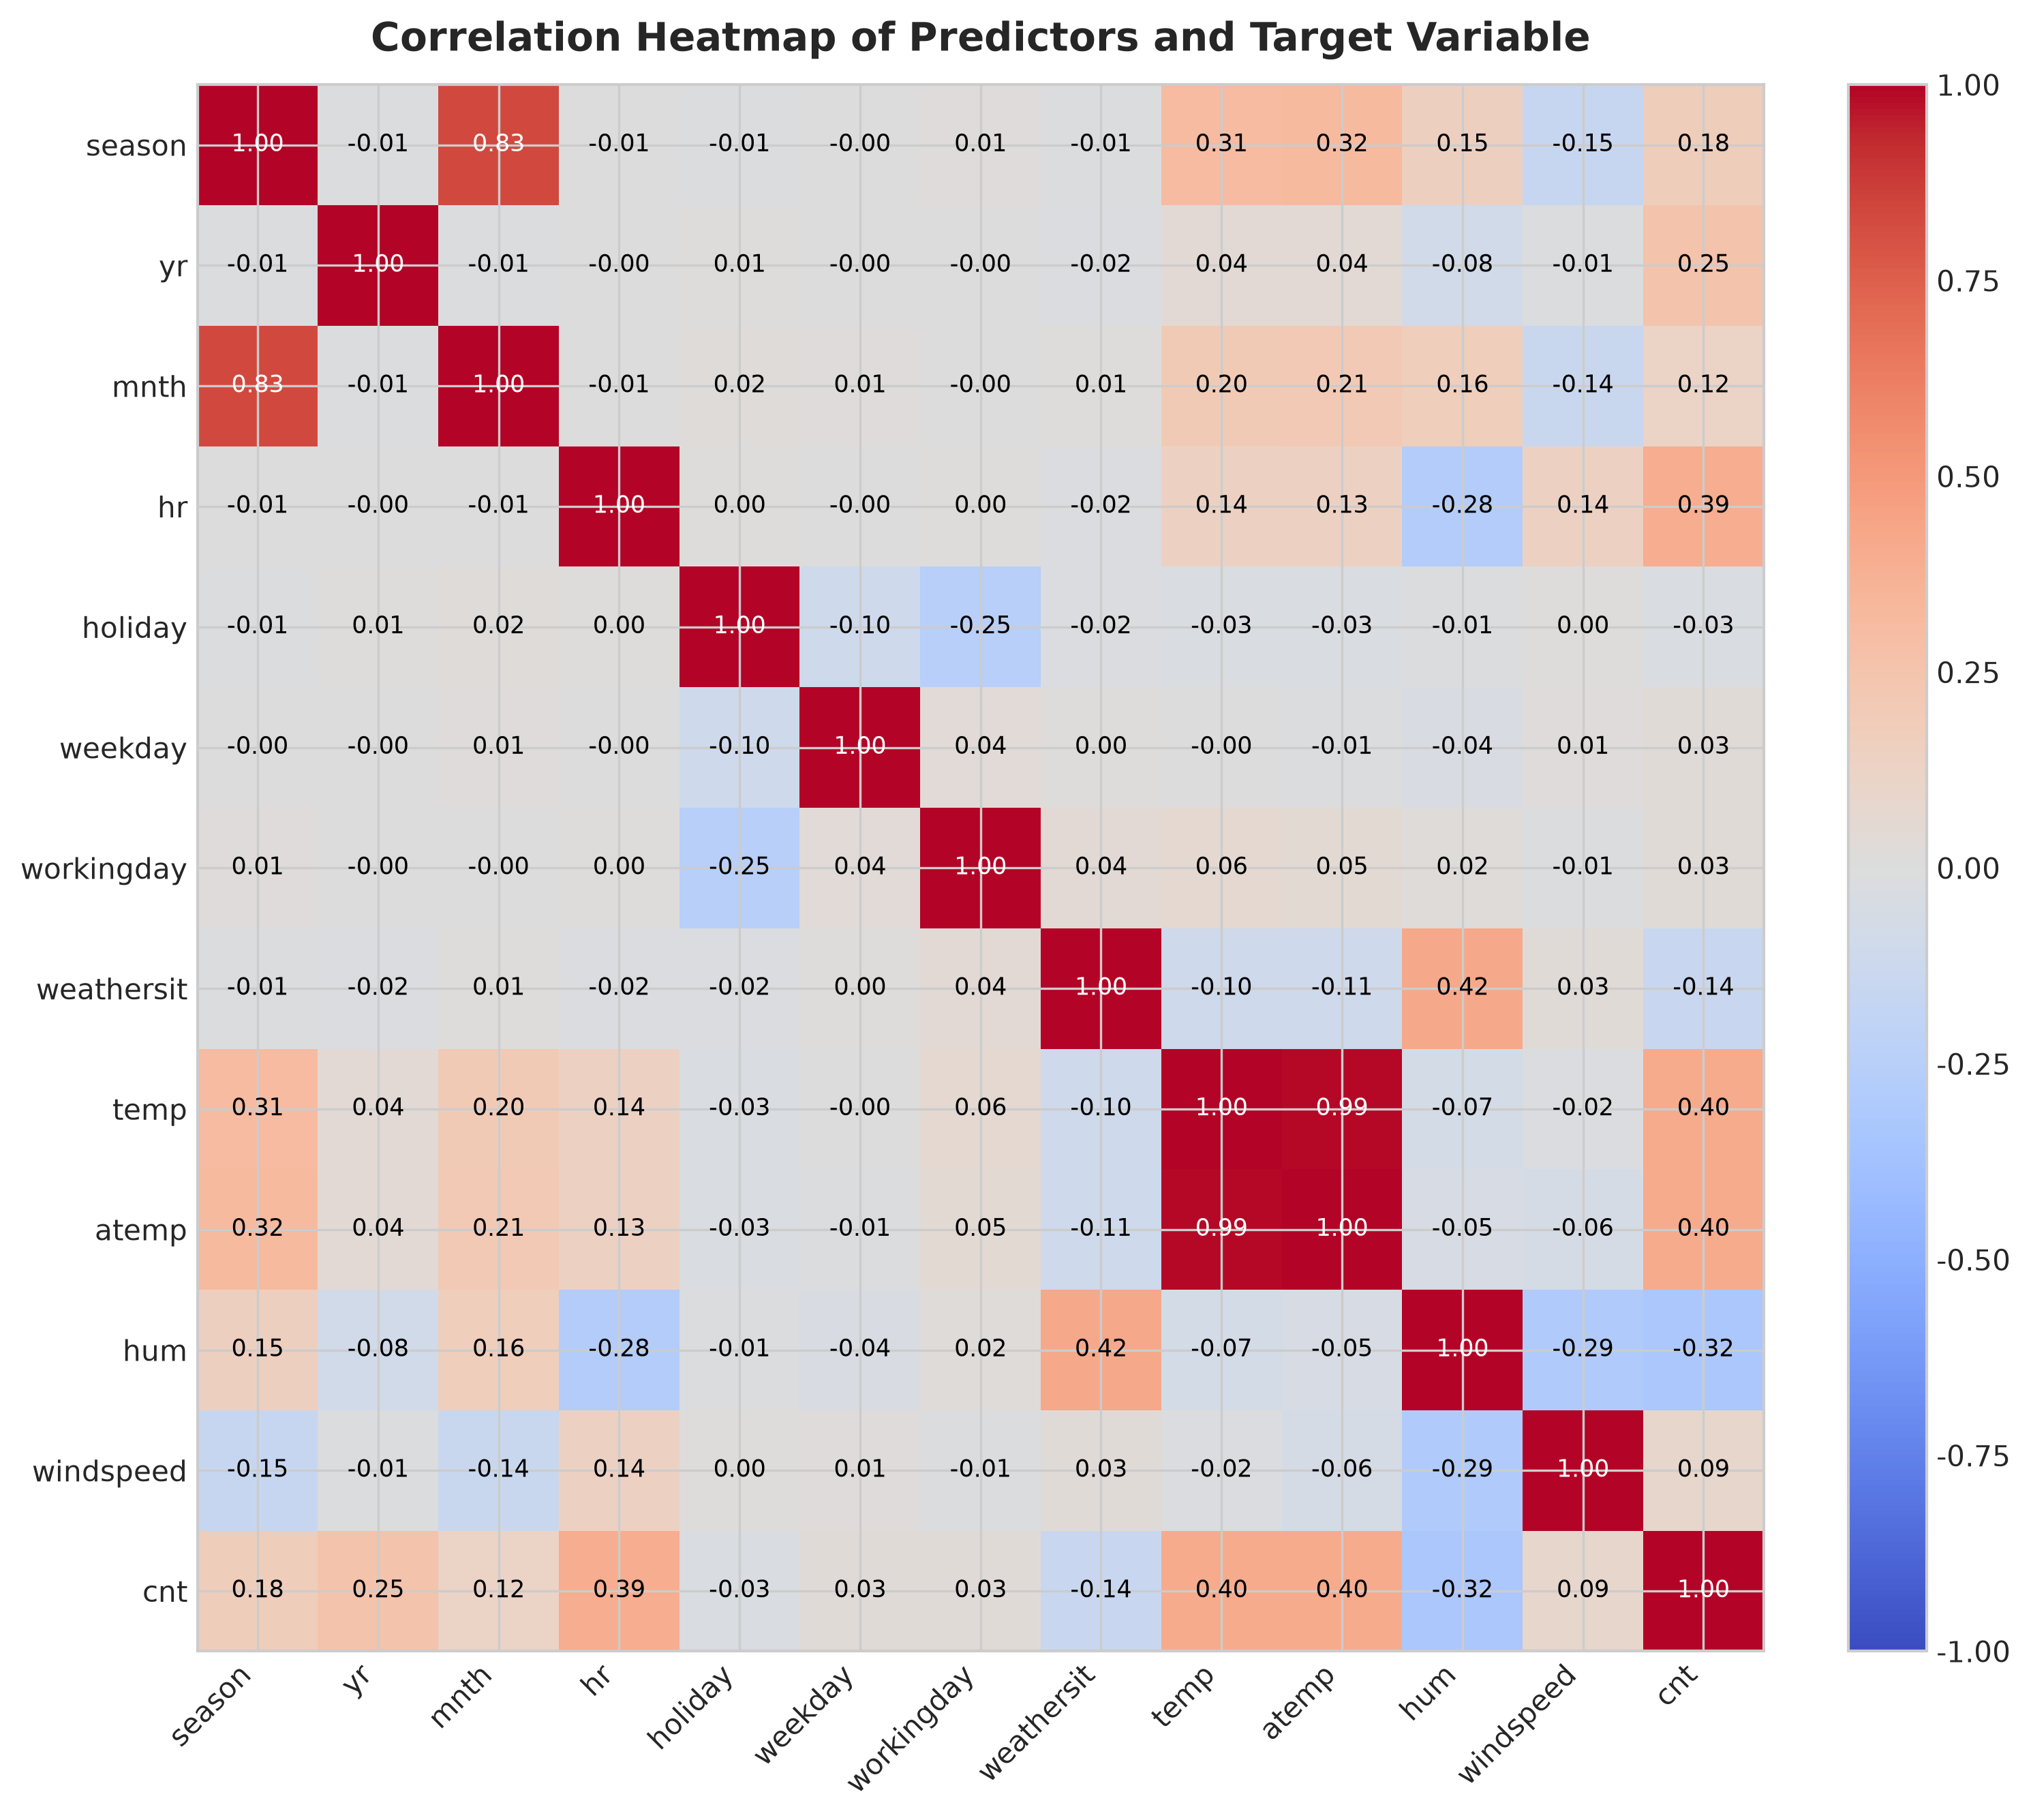

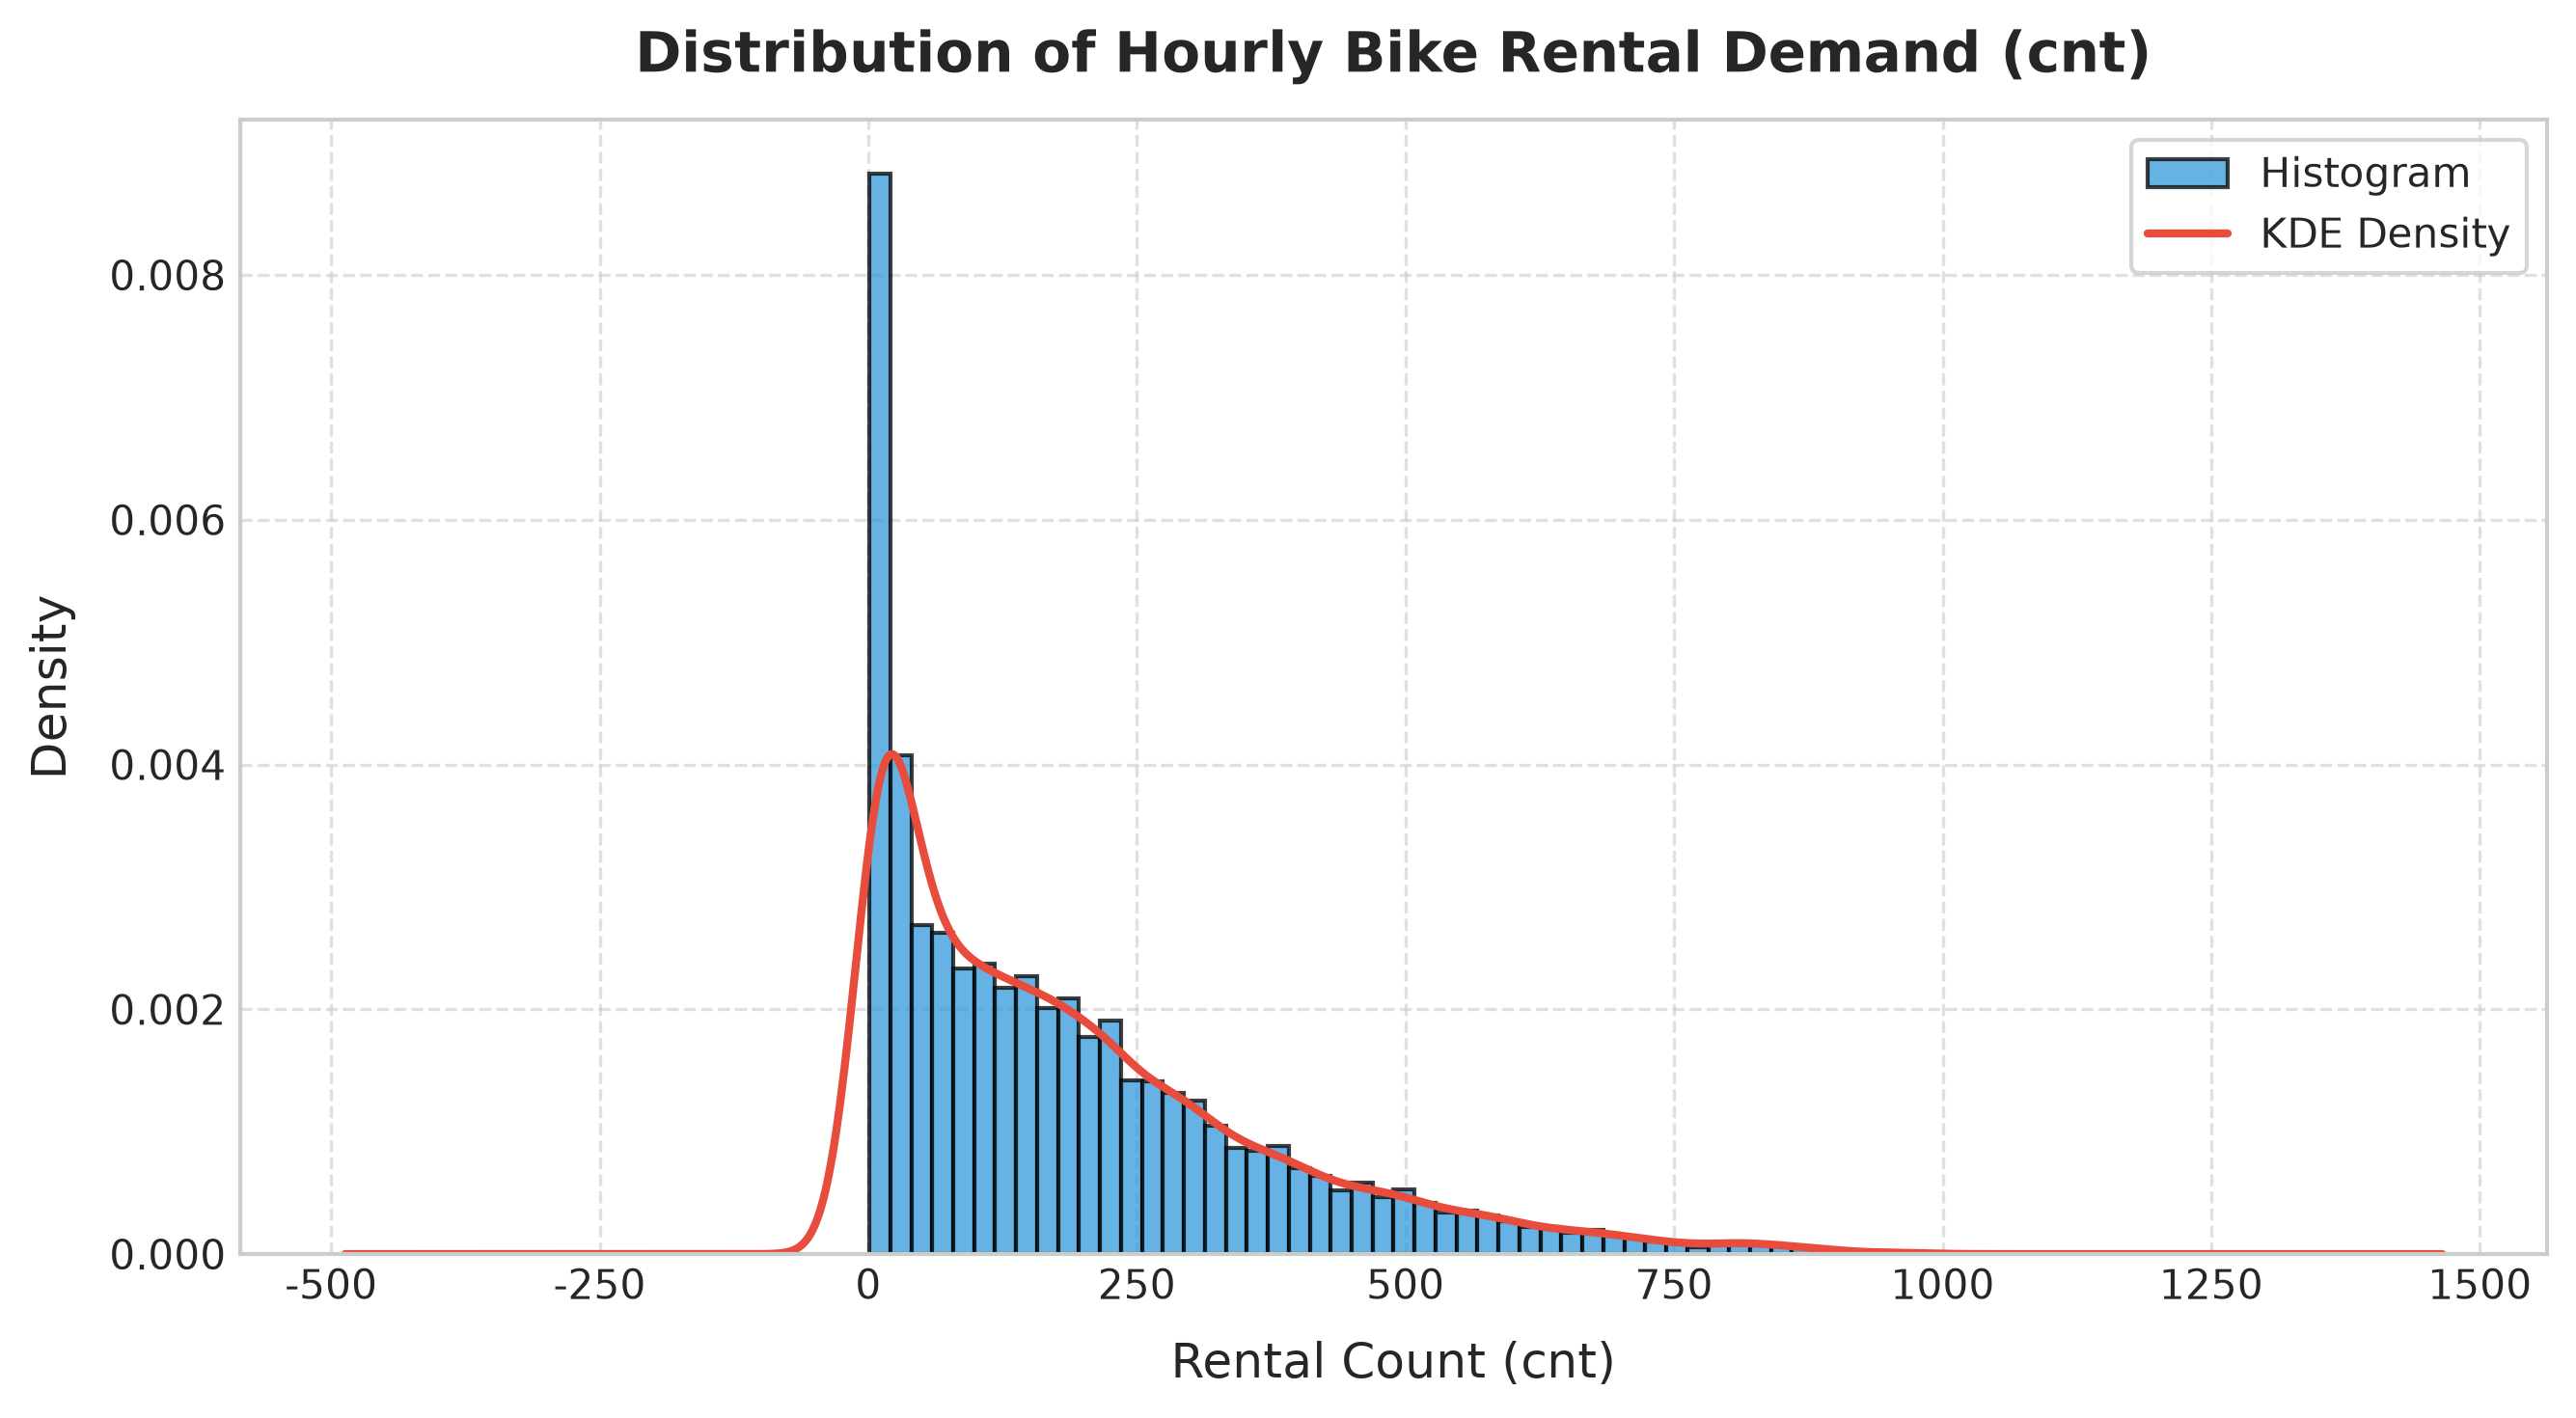

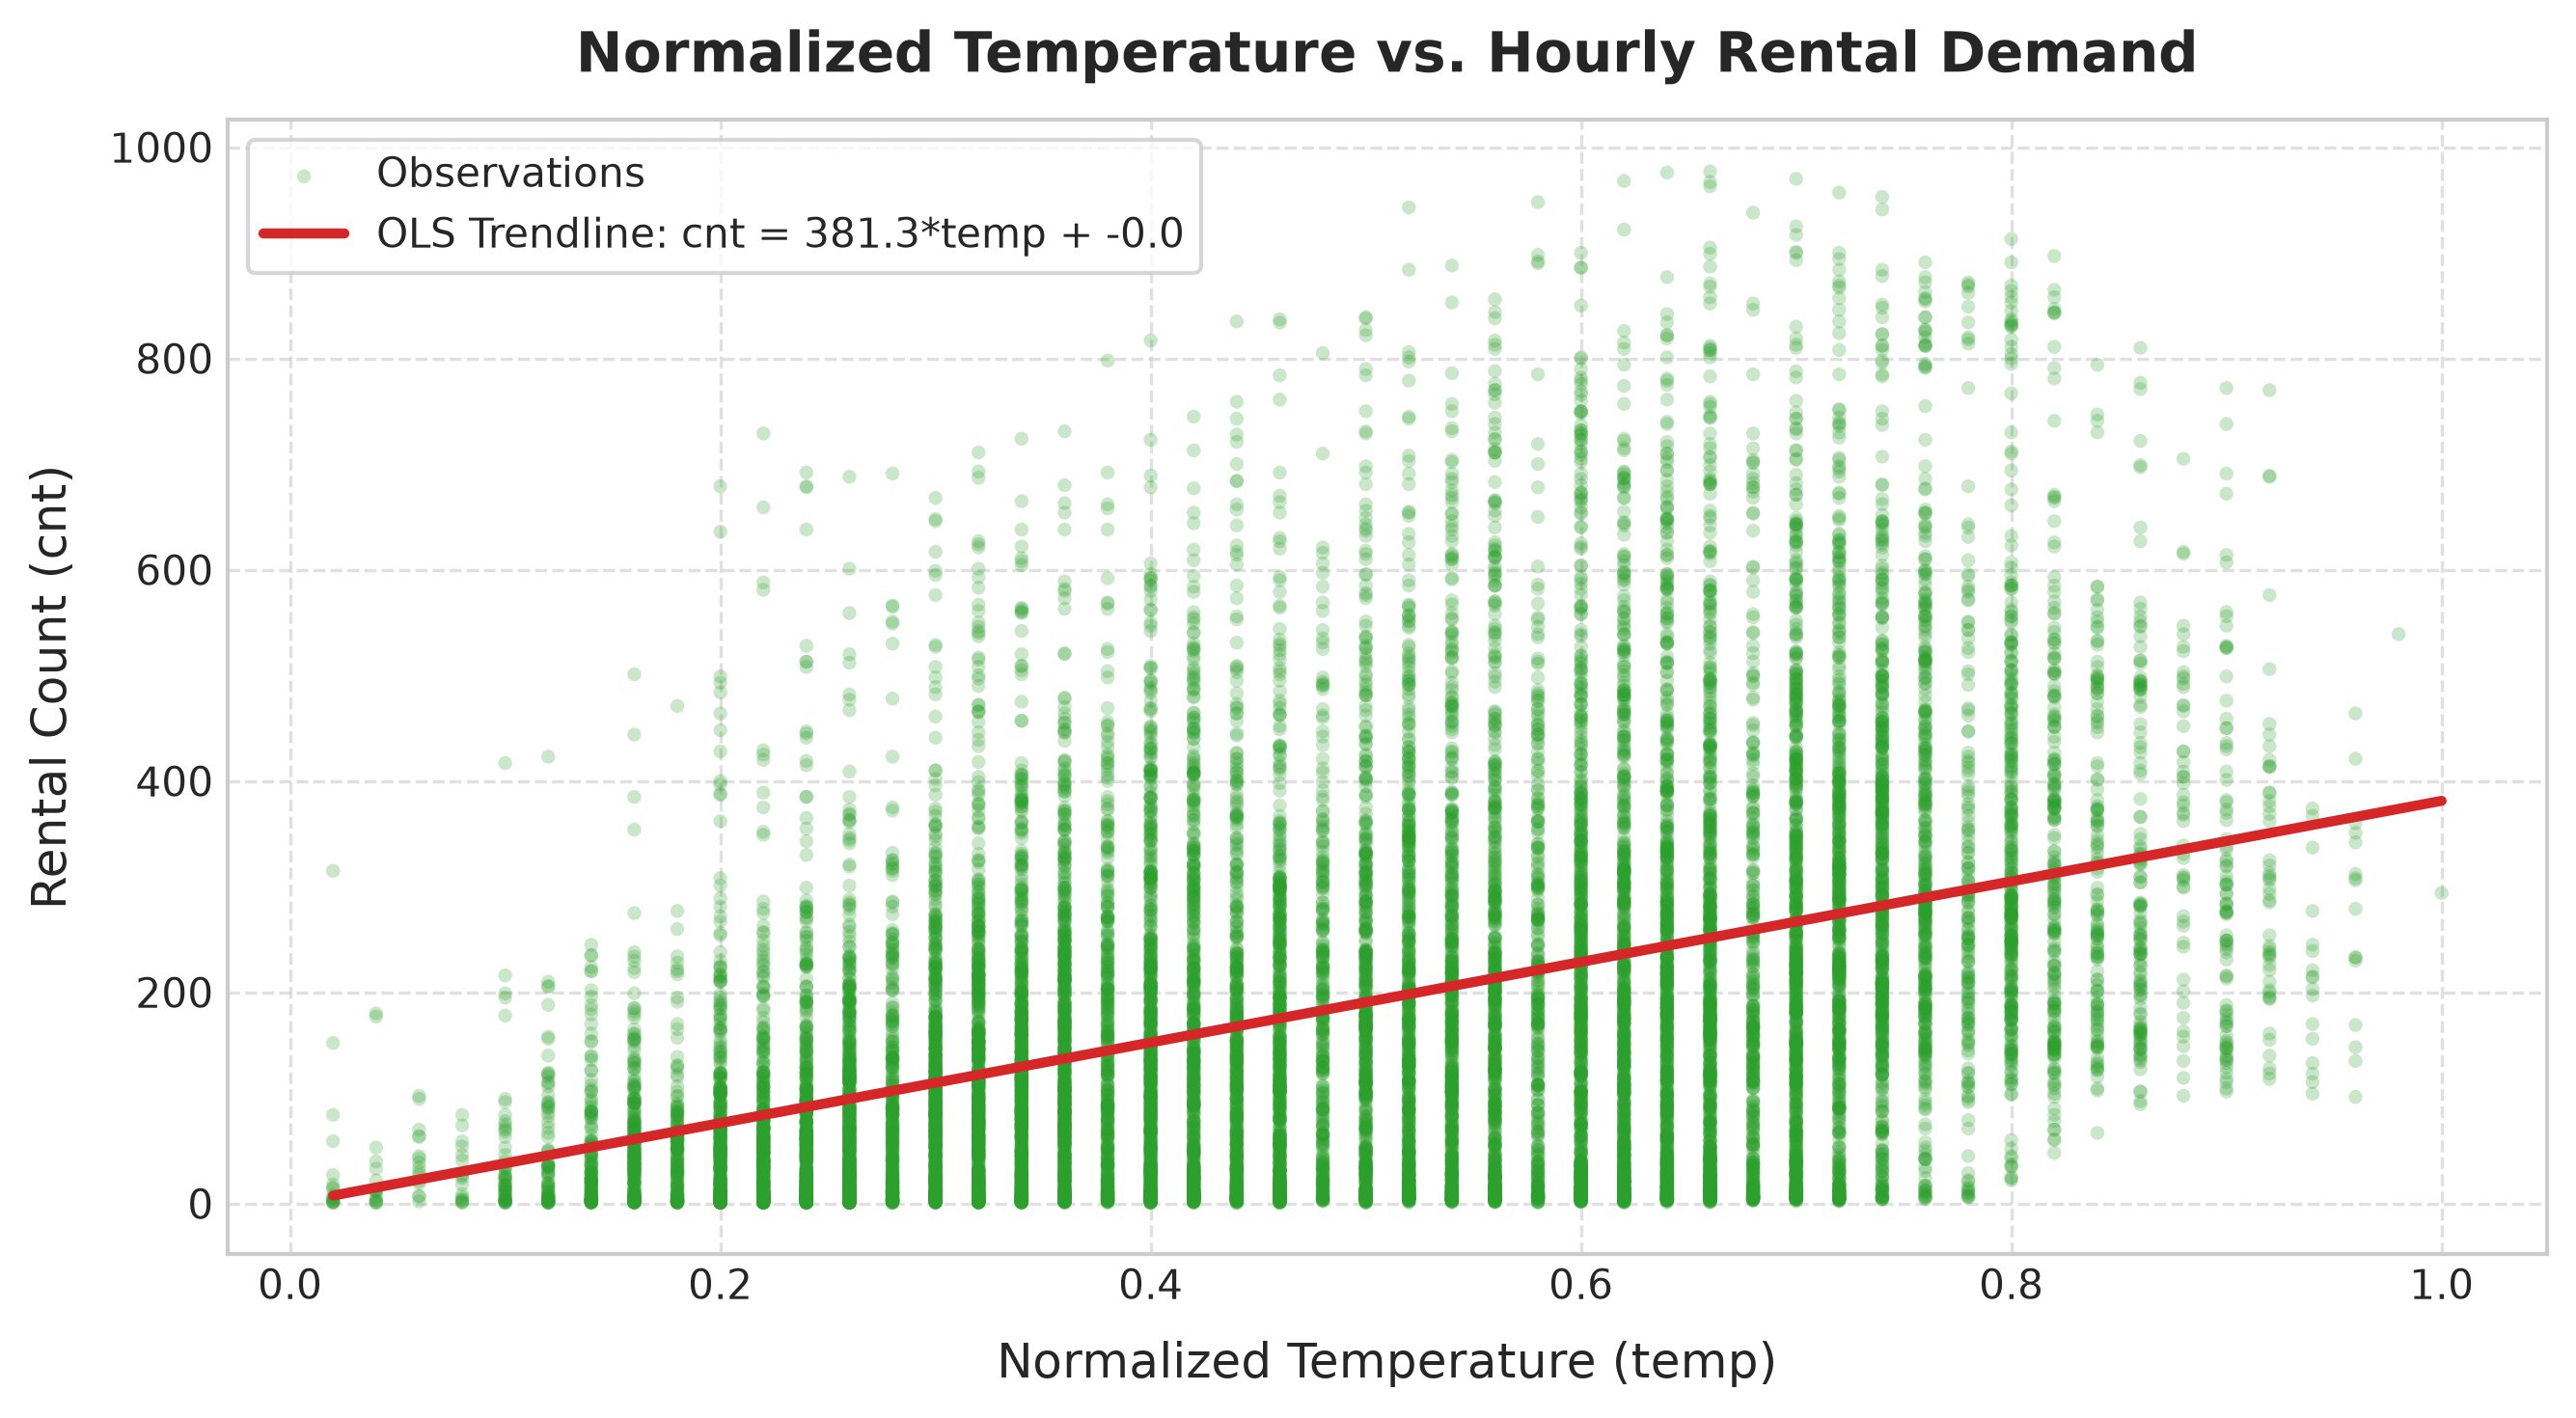

In [4]:
# Figure 1: Hourly Rental Demand (24 小時租借需求趨勢)
fig1, ax1 = plt.subplots(figsize=(10, 5), dpi=300)
hourly_avg = df.groupby('hr')['cnt'].mean()
ax1.plot(hourly_avg.index, hourly_avg.values, marker='o', color='#1f77b4', linewidth=2.5, markersize=6)
ax1.set_title("Average Bike Rental Demand by Hour", fontsize=14, fontweight='bold', pad=12)
ax1.set_xlabel("Hour of Day", fontsize=12, labelpad=8)
ax1.set_ylabel("Average Rental Count", fontsize=12, labelpad=8)
ax1.set_xticks(range(0, 24))
ax1.grid(True, linestyle='--', alpha=0.6)
fig1.tight_layout()
fig1.savefig(os.path.join(FIGURES_DIR, "hourly_demand.png"), dpi=300)
plt.show()

# Figure 2: Correlation Heatmap (相關係數矩陣熱力圖)
candidate_numeric = ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday',
                     'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt']
corr_matrix = df[candidate_numeric].corr()

fig2, ax2 = plt.subplots(figsize=(11, 9), dpi=300)
im = ax2.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
ax2.set_xticks(range(len(candidate_numeric)))
ax2.set_yticks(range(len(candidate_numeric)))
ax2.set_xticklabels(candidate_numeric, rotation=45, ha='right', fontsize=10)
ax2.set_yticklabels(candidate_numeric, fontsize=10)
ax2.set_title("Correlation Heatmap of Predictors and Target Variable", fontsize=14, fontweight='bold', pad=12)
fig2.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

for i in range(len(candidate_numeric)):
    for j in range(len(candidate_numeric)):
        val = corr_matrix.iloc[i, j]
        text_color = "white" if abs(val) > 0.55 else "black"
        ax2.text(j, i, f"{val:.2f}", ha="center", va="center", color=text_color, fontsize=8.5)

fig2.tight_layout()
fig2.savefig(os.path.join(FIGURES_DIR, "correlation_heatmap.png"), dpi=300)
plt.show()

# Figure 3: Target Distribution Histogram & KDE (目標變數分佈)
fig3, ax3 = plt.subplots(figsize=(9, 5), dpi=300)
ax3.hist(df['cnt'], bins=50, color='#3498db', edgecolor='black', alpha=0.75, density=True, label='Histogram')
df['cnt'].plot(kind='kde', ax=ax3, color='#e74c3c', linewidth=2, label='KDE Density')
ax3.set_title("Distribution of Hourly Bike Rental Demand (cnt)", fontsize=14, fontweight='bold', pad=12)
ax3.set_xlabel("Rental Count (cnt)", fontsize=12, labelpad=8)
ax3.set_ylabel("Density", fontsize=12, labelpad=8)
ax3.legend(frameon=True, facecolor='white', loc='upper right')
ax3.grid(True, linestyle='--', alpha=0.6)
fig3.tight_layout()
fig3.savefig(os.path.join(FIGURES_DIR, "target_distribution.png"), dpi=300)
plt.show()

# Figure 4: Temperature vs. Demand (氣溫與需求散佈圖)
fig4, ax4 = plt.subplots(figsize=(9, 5), dpi=300)
ax4.scatter(df['temp'], df['cnt'], alpha=0.25, color='#2ca02c', s=12, edgecolors='none', label='Observations')
m, b = np.polyfit(df['temp'], df['cnt'], 1)
x_vals = np.linspace(df['temp'].min(), df['temp'].max(), 100)
ax4.plot(x_vals, m * x_vals + b, color='#d62728', linewidth=2.5, label=f'OLS Trendline: cnt = {m:.1f}*temp + {b:.1f}')
ax4.set_title("Normalized Temperature vs. Hourly Rental Demand", fontsize=14, fontweight='bold', pad=12)
ax4.set_xlabel("Normalized Temperature (temp)", fontsize=12, labelpad=8)
ax4.set_ylabel("Rental Count (cnt)", fontsize=12, labelpad=8)
ax4.legend(frameon=True, facecolor='white', loc='upper left')
ax4.grid(True, linestyle='--', alpha=0.6)
fig4.tight_layout()
fig4.savefig(os.path.join(FIGURES_DIR, "temperature_vs_demand.png"), dpi=300)
plt.show()

### 5. 時間序列嚴格時序切分 (Step 3 — Chronological Data Split)
#### 核心研究問題定義
「給定特定小時之時間、日曆與氣象環境資訊，預測該小時之自行車租借總需求量。」

#### 切分設計原則
1. **絕不隨機打亂 (No Random Shuffle):** 防止未來資訊外洩（Temporal Data Leakage）。
2. **完整日曆天邊界 (Full Calendar-Day Boundaries):** 自行車租借具備強烈的日週期性，切分點精準鎖定在日曆天交界（00:00:00），確保同一天的觀測值絕不跨子集。
3. **切分比例設定:**
   - **訓練集 (Training Set, ~70%):** 512 天，用於模型訓練、交叉驗證與特徵選取。
   - **校準集 (Calibration Set, ~15%):** 110 天，完全保留予未來 Phase 3 構建 Split Conformal Prediction 預測區間。
   - **測試集 (Test Set, ~15%):** 109 天，完全封存保留予最終泛化評估。
4. **隔離規範:** 嚴禁在 Phase 1 與 Phase 2 窺探、訓練或評估 Calibration Set 與 Test Set。

In [5]:
# 依據完整日曆天進行程式化時序切分
unique_days = df['dteday'].drop_duplicates().sort_values().reset_index(drop=True)
total_calendar_days = len(unique_days)

n_train_days = int(round(total_calendar_days * 0.70))
n_calib_days = int(round(total_calendar_days * 0.15))
n_test_days = total_calendar_days - n_train_days - n_calib_days

train_dates = unique_days.iloc[:n_train_days].reset_index(drop=True)
calib_dates = unique_days.iloc[n_train_days:n_train_days + n_calib_days].reset_index(drop=True)
test_dates = unique_days.iloc[n_train_days + n_calib_days:].reset_index(drop=True)

train_day_set = set(train_dates)
calib_day_set = set(calib_dates)
test_day_set = set(test_dates)

train_data = df[df['dteday'].isin(train_day_set)].copy()
calib_data = df[df['dteday'].isin(calib_day_set)].copy()
test_data = df[df['dteday'].isin(test_day_set)].copy()

# 嚴格驗證集合無重疊與時序單調性
assert len(train_day_set.intersection(calib_day_set)) == 0, "Train 與 Calib 日期重疊！"
assert len(train_day_set.intersection(test_day_set)) == 0, "Train 與 Test 日期重疊！"
assert len(calib_day_set.intersection(test_day_set)) == 0, "Calib 與 Test 日期重疊！"
assert train_data['datetime'].max() < calib_data['datetime'].min(), "Train 與 Calib 時序錯置！"
assert calib_data['datetime'].max() < test_data['datetime'].min(), "Calib 與 Test 時序錯置！"

split_report = {
    "total_observations": len(df),
    "total_calendar_days": total_calendar_days,
    "subsets": {
        "train": {
            "days": len(train_day_set),
            "observations": len(train_data),
            "percentage": round(len(train_data) / len(df) * 100, 2),
            "start_date": str(train_data['dteday'].min()),
            "end_date": str(train_data['dteday'].max()),
            "start_timestamp": str(train_data['datetime'].min()),
            "end_timestamp": str(train_data['datetime'].max())
        },
        "calibration": {
            "days": len(calib_day_set),
            "observations": len(calib_data),
            "percentage": round(len(calib_data) / len(df) * 100, 2),
            "start_date": str(calib_data['dteday'].min()),
            "end_date": str(calib_data['dteday'].max()),
            "start_timestamp": str(calib_data['datetime'].min()),
            "end_timestamp": str(calib_data['datetime'].max())
        },
        "test": {
            "days": len(test_day_set),
            "observations": len(test_data),
            "percentage": round(len(test_data) / len(df) * 100, 2),
            "start_date": str(test_data['dteday'].min()),
            "end_date": str(test_data['dteday'].max()),
            "start_timestamp": str(test_data['datetime'].min()),
            "end_timestamp": str(test_data['datetime'].max())
        }
    }
}

with open(os.path.join(RESULTS_DIR, "data_split_summary.json"), "w", encoding="utf-8") as f:
    json.dump(split_report, f, indent=2, ensure_ascii=False)

for subset_name, sub in split_report['subsets'].items():
    print(f"[{subset_name.upper():11s}] 天數: {sub['days']:3d} 天 | 筆數: {sub['observations']:5d} ({sub['percentage']:5.2f}%) | 區間: {sub['start_date']} 至 {sub['end_date']}")

[TRAIN      ] 天數: 512 天 | 筆數: 12163 (69.99%) | 區間: 2011-01-01 至 2012-05-26
[CALIBRATION] 天數: 110 天 | 筆數:  2640 (15.19%) | 區間: 2012-05-27 至 2012-09-13
[TEST       ] 天數: 109 天 | 筆數:  2576 (14.82%) | 區間: 2012-09-14 至 2012-12-31


### 6. 特徵預處理管線 (Step 4 — Preprocessing Pipeline)
#### 預處理架構設計
我們採用 `scikit-learn` 之 `ColumnTransformer` 構建模組化管線：
1. **類別型特徵（Categorical Predictors, 5 個）:** `season`, `mnth`, `hr`, `weekday`, `weathersit`，使用 `OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False)`，避免虛擬變數陷阱（Dummy Variable Trap）。
2. **數值/二元型特徵（Numeric & Binary Predictors, 7 個）:** `yr`, `holiday`, `workingday`, `temp`, `atemp`, `hum`, `windspeed`，直接傳遞（`passthrough`）。
3. **維度對應:** 12 個原生特徵展開為 **53 個模型輸入特徵欄位**。
4. **管線學習原則:** 預處理參數嚴格僅在訓練集擬合（Fit）。

In [6]:
categorical_features = ['season', 'mnth', 'hr', 'weekday', 'weathersit']
continuous_numeric = ['temp', 'atemp', 'hum', 'windspeed']
binary_features = ['yr', 'holiday', 'workingday']
numeric_features = continuous_numeric + binary_features
all_predictors = categorical_features + numeric_features
target_col = 'cnt'

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
        ('num', 'passthrough', numeric_features)
    ],
    remainder='drop'
)

X_train = train_data[all_predictors]
y_train = train_data[target_col]

preprocessor.fit(X_train)
cat_encoded_cols = list(preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features))
total_encoded_features = cat_encoded_cols + numeric_features

feature_mapping_df = pd.DataFrame({
    "encoded_col_idx": range(len(total_encoded_features)),
    "encoded_feature_name": total_encoded_features,
    "source_feature": [col.split('_')[0] if col.startswith(tuple(categorical_features)) else col for col in total_encoded_features],
    "encoding_type": ["categorical_dummy" if i < len(cat_encoded_cols) else "numeric_or_binary" for i in range(len(total_encoded_features))]
})
feature_mapping_df.to_csv(os.path.join(RESULTS_DIR, "encoded_feature_names.csv"), index=False)
print(f"原生特徵數量: {len(all_predictors)} | 編碼後模型特徵數量: {len(total_encoded_features)}")

原生特徵數量: 12 | 編碼後模型特徵數量: 53


### 7. 基準模型構建與時序交叉驗證 (Step 5 — Baseline OLS Model)
#### 模型設定與驗證
採用 `sklearn.linear_model.LinearRegression` 作為基準模型（M1），並以 `DummyRegressor(strategy="mean")` 作為無資訊對照。
在訓練集內部嚴格執行 **Date-Bounded Expanding Window 5-Fold CV**，記錄各折疊驗證指標。

In [7]:
# Date-Bounded Expanding Window 5-Fold CV 設定
train_unique_dates = unique_days.iloc[:n_train_days].reset_index(drop=True)
tscv_dates = TimeSeriesSplit(n_splits=5)
cv_splits = []

for fold, (tr_date_idx, val_date_idx) in enumerate(tscv_dates.split(train_unique_dates), 1):
    fold_tr_dates = set(train_unique_dates.iloc[tr_date_idx])
    fold_val_dates = set(train_unique_dates.iloc[val_date_idx])
    assert len(fold_tr_dates.intersection(fold_val_dates)) == 0
    
    cv_splits.append({
        'fold': fold,
        'tr_mask': train_data['dteday'].isin(fold_tr_dates),
        'val_mask': train_data['dteday'].isin(fold_val_dates),
        'tr_dates': fold_tr_dates,
        'val_dates': fold_val_dates,
        'tr_start': str(train_unique_dates.iloc[tr_date_idx].min()),
        'tr_end': str(train_unique_dates.iloc[tr_date_idx].max()),
        'val_start': str(train_unique_dates.iloc[val_date_idx].min()),
        'val_end': str(train_unique_dates.iloc[val_date_idx].max()),
        'n_tr_days': len(fold_tr_dates),
        'n_val_days': len(fold_val_dates)
    })

# 擬合全訓練集 OLS
ols_pipeline = Pipeline([('preprocessor', preprocessor), ('regressor', LinearRegression())])
ols_pipeline.fit(X_train, y_train)
y_train_pred = ols_pipeline.predict(X_train)

m1_tr_mae = float(mean_absolute_error(y_train, y_train_pred))
m1_tr_mse = float(mean_squared_error(y_train, y_train_pred))
m1_tr_rmse = float(np.sqrt(m1_tr_mse))
m1_tr_r2 = float(r2_score(y_train, y_train_pred))

# 執行 M1 CV
m1_cv_records = []
for split in cv_splits:
    X_tr_f, y_tr_f = train_data.loc[split['tr_mask'], all_predictors], train_data.loc[split['tr_mask'], target_col]
    X_va_f, y_va_f = train_data.loc[split['val_mask'], all_predictors], train_data.loc[split['val_mask'], target_col]
    
    f_pre = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
        ('num', 'passthrough', numeric_features)
    ], remainder='drop')
    f_pipe = Pipeline([('preprocessor', f_pre), ('regressor', LinearRegression())])
    f_pipe.fit(X_tr_f, y_tr_f)
    pred_va = f_pipe.predict(X_va_f)
    
    f_dummy = DummyRegressor(strategy="mean")
    f_dummy.fit(X_tr_f, y_tr_f)
    dummy_pred_va = f_dummy.predict(X_va_f)
    
    mae = float(mean_absolute_error(y_va_f, pred_va))
    mse = float(mean_squared_error(y_va_f, pred_va))
    rmse = float(np.sqrt(mse))
    r2 = float(r2_score(y_va_f, pred_va))
    dummy_rmse = float(np.sqrt(mean_squared_error(y_va_f, dummy_pred_va)))
    
    m1_cv_records.append({
        "fold": split['fold'],
        "train_start_date": split['tr_start'],
        "train_end_date": split['tr_end'],
        "val_start_date": split['val_start'],
        "val_end_date": split['val_end'],
        "n_train_days": split['n_tr_days'],
        "n_val_days": split['n_val_days'],
        "n_train_samples": int(len(X_tr_f)),
        "n_val_samples": int(len(X_va_f)),
        "val_mae": round(mae, 4),
        "val_mse": round(mse, 4),
        "val_rmse": round(rmse, 4),
        "val_r2": round(r2, 4),
        "dummy_val_rmse": round(dummy_rmse, 4)
    })

m1_cv_df = pd.DataFrame(m1_cv_records)
m1_cv_df.to_csv(os.path.join(RESULTS_DIR, "baseline_cv_results.csv"), index=False)

print("=== M1 OLS Baseline 評估結果 ===")
print(f"Training RMSE: {m1_tr_rmse:.4f} | R²: {m1_tr_r2:.4f}")
print(f"5-Fold CV Validation RMSE Mean: {m1_cv_df['val_rmse'].mean():.4f} (std: {m1_cv_df['val_rmse'].std():.4f})")
print(f"5-Fold CV Validation MAE Mean:  {m1_cv_df['val_mae'].mean():.4f}")
print(f"5-Fold CV Validation R² Mean:   {m1_cv_df['val_r2'].mean():.4f}")
print(f"Dummy Mean CV RMSE Mean:        {m1_cv_df['dummy_val_rmse'].mean():.4f}")

=== M1 OLS Baseline 評估結果 ===
Training RMSE: 85.4821 | R²: 0.6861
5-Fold CV Validation RMSE Mean: 108.6860 (std: 15.3604)
5-Fold CV Validation MAE Mean:  81.2065
5-Fold CV Validation R² Mean:   0.4624
Dummy Mean CV RMSE Mean:        164.7931


### 8. 遞迴特徵消除 (Phase 2 Step 1 — Feature Selection with RFE)
#### 為什麼需要特徵選取？
1. **維度災難與方差控制:** 雖然多元線性迴歸在全特徵（53 維）下能配適訓練資料，但過多弱相關特徵會增加模型參數估計方差，降低泛化能力。
2. **多重共線性排除:** 諸如 `temp` 與 `atemp`（$r=0.99$）等高共線性特徵，會導致迴歸矩陣條件數過大。
3. **模型簡約性 (Parsimony):** 遵循奧卡姆剃刀原則，在預測效能相當的前提下，特徵數越少的模型越具備可解釋性與強健性。

#### RFE 演算法運作機制
**遞迴特徵消除 (Recursive Feature Elimination, RFE)** 是一種貪婪後向淘汰（Greedy Backward Elimination）方法：
1. 以全部候選特徵擬合基礎模型（`LinearRegression`）。
2. 計算各特徵的權重絕對值 $|eta_j|$ 或重要性分數。
3. 剔除重要性最低之特徵，並以剩餘特徵**重新擬合模型**（重新估計剩餘特徵的係數）。
4. 重複上述步驟，直到特徵數量縮減至指定數量 $k$。

> [!IMPORTANT]
> **編碼欄位選取說明:** 在本研究中，RFE 篩選之對象為 One-Hot Encoding 展開後之 **53 個模型輸入欄位**，而非直接剔除整組原始類別。此舉允許模型細緻保留顯著的特定小時或季節虛擬變數，而剔除無顯著效應之時間段。

RFE k= 5 -> CV RMSE Mean: 128.5602 (std: 28.6627)


RFE k=10 -> CV RMSE Mean: 122.2297 (std: 26.7931)


RFE k=15 -> CV RMSE Mean: 114.1164 (std: 26.3642)


RFE k=20 -> CV RMSE Mean: 108.4448 (std: 26.4776)


RFE k=25 -> CV RMSE Mean: 108.4977 (std: 16.4116)


RFE k=30 -> CV RMSE Mean: 107.4394 (std: 14.7812)


RFE k=35 -> CV RMSE Mean: 107.7955 (std: 14.6137)


RFE k=40 -> CV RMSE Mean: 108.6854 (std: 14.2962)


RFE k=45 -> CV RMSE Mean: 108.6561 (std: 13.8130)


RFE k=50 -> CV RMSE Mean: 108.6865 (std: 13.7374)
RFE k=53 -> CV RMSE Mean: 108.6860 (std: 13.7388)

[RFE 最佳特徵數] Best k = 30 (Mean CV RMSE: 107.4394)


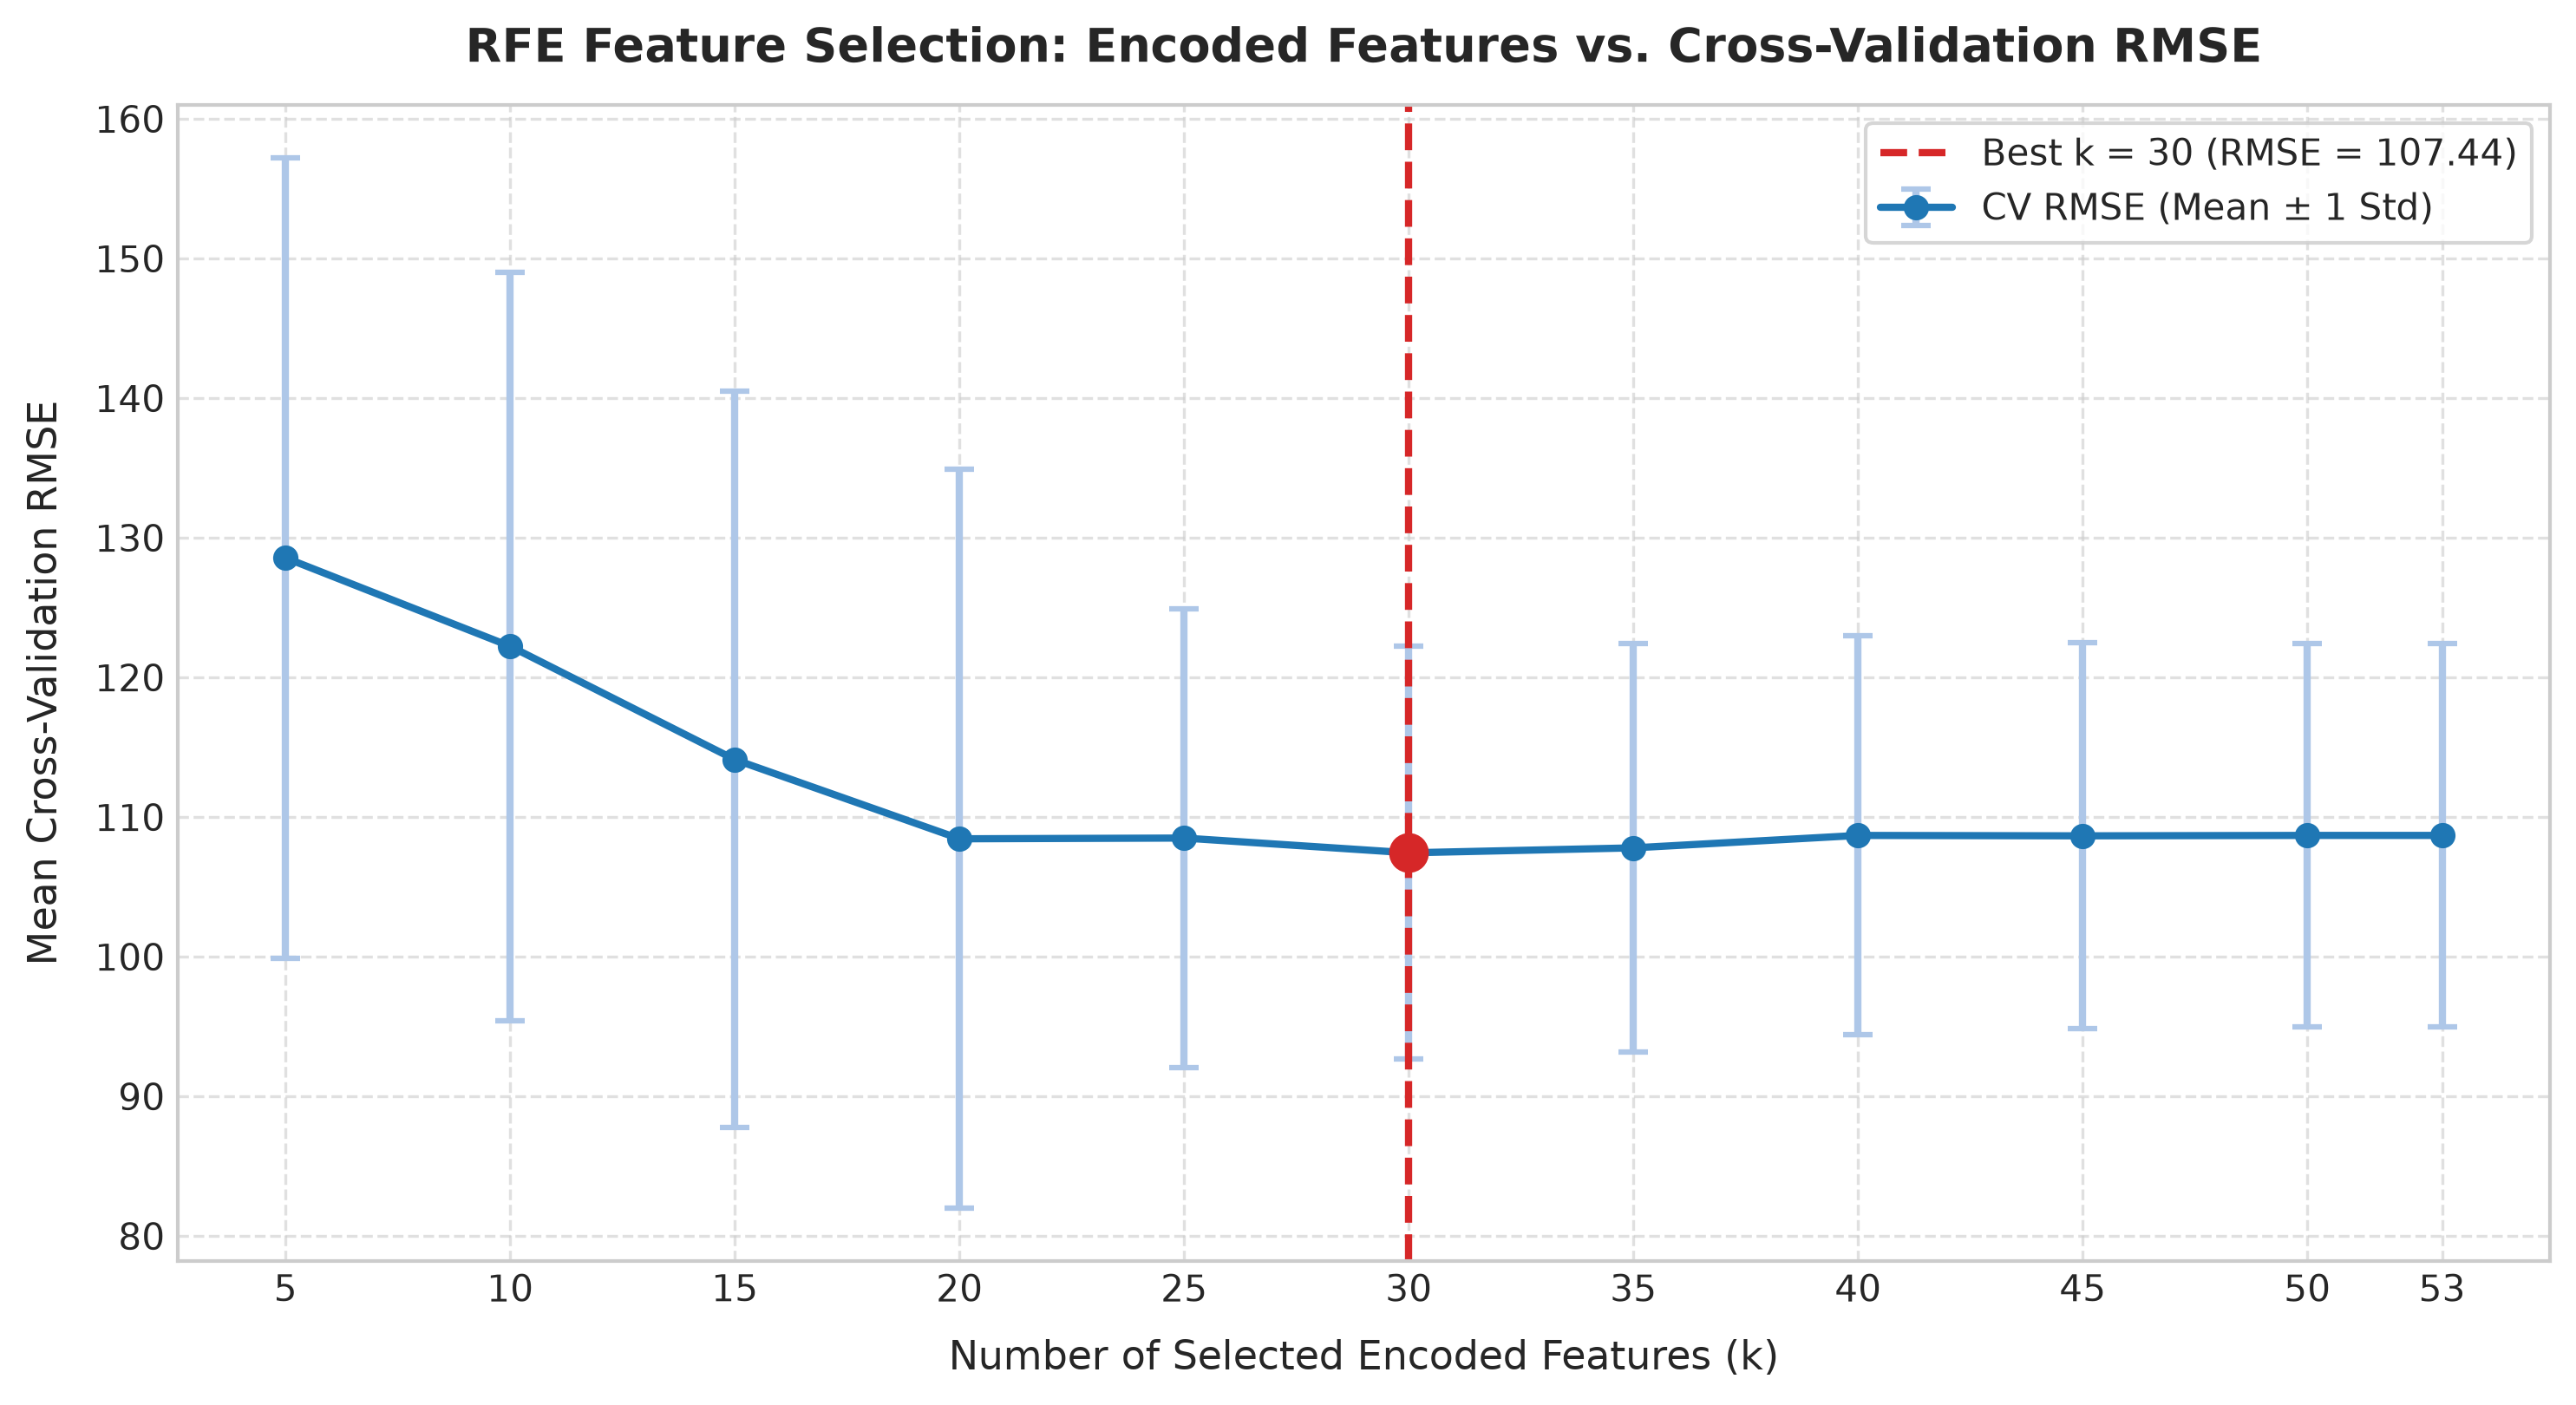

In [8]:
# RFE 網格搜尋: k ∈ [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 53]
k_candidate_grid = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 53]
rfe_records = []

# 預先為每折進行獨立編碼轉換以提升運算效率 (零外洩)
fold_rfe_data = []
for split in cv_splits:
    X_tr_f = train_data.loc[split['tr_mask'], all_predictors]
    y_tr_f = train_data.loc[split['tr_mask'], target_col]
    X_va_f = train_data.loc[split['val_mask'], all_predictors]
    y_va_f = train_data.loc[split['val_mask'], target_col]
    
    f_pre = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
        ('num', 'passthrough', numeric_features)
    ], remainder='drop')
    X_tr_t = f_pre.fit_transform(X_tr_f)
    X_va_t = f_pre.transform(X_va_f)
    fold_rfe_data.append((X_tr_t, y_tr_f.values, X_va_t, y_va_f.values, split['fold']))

rfe_summary_by_k = {}

for k in k_candidate_grid:
    fold_k_rmses = []
    fold_k_maes = []
    fold_k_mses = []
    fold_k_r2s = []
    
    for X_tr_t, y_tr_v, X_va_t, y_val_v, fold_id in fold_rfe_data:
        actual_k = min(k, X_tr_t.shape[1])
        rfe = RFE(estimator=LinearRegression(), n_features_to_select=actual_k)
        rfe.fit(X_tr_t, y_tr_v)
        val_pred = rfe.predict(X_va_t)
        
        mae = float(mean_absolute_error(y_val_v, val_pred))
        mse = float(mean_squared_error(y_val_v, val_pred))
        rmse = float(np.sqrt(mse))
        r2 = float(r2_score(y_val_v, val_pred))
        
        fold_k_rmses.append(rmse)
        fold_k_maes.append(mae)
        fold_k_mses.append(mse)
        fold_k_r2s.append(r2)
        
        rfe_records.append({
            'k': k,
            'fold': fold_id,
            'selected_feature_count': actual_k,
            'val_mae': round(mae, 4),
            'val_mse': round(mse, 4),
            'val_rmse': round(rmse, 4),
            'val_r2': round(r2, 4)
        })
    
    rfe_summary_by_k[k] = {
        'mean_rmse': float(np.mean(fold_k_rmses)),
        'std_rmse': float(np.std(fold_k_rmses)),
        'mean_mae': float(np.mean(fold_k_maes)),
        'mean_mse': float(np.mean(fold_k_mses)),
        'mean_r2': float(np.mean(fold_k_r2s)),
        'fold_rmses': fold_k_rmses
    }
    print(f"RFE k={k:2d} -> CV RMSE Mean: {rfe_summary_by_k[k]['mean_rmse']:.4f} (std: {rfe_summary_by_k[k]['std_rmse']:.4f})")

rfe_df = pd.DataFrame(rfe_records)
rfe_df.to_csv(os.path.join(RESULTS_DIR, "rfe_search_results.csv"), index=False)

best_k = min(rfe_summary_by_k.keys(), key=lambda x: rfe_summary_by_k[x]['mean_rmse'])
print(f"\n[RFE 最佳特徵數] Best k = {best_k} (Mean CV RMSE: {rfe_summary_by_k[best_k]['mean_rmse']:.4f})")

# 以完整訓練集重新擬合最佳 RFE Pipeline
m2_preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
    ('num', 'passthrough', numeric_features)
], remainder='drop')
X_train_trans = m2_preprocessor.fit_transform(X_train)
m2_rfe = RFE(estimator=LinearRegression(), n_features_to_select=best_k)
m2_rfe.fit(X_train_trans, y_train)

m2_tr_pred = m2_rfe.predict(X_train_trans)
m2_tr_mae = float(mean_absolute_error(y_train, m2_tr_pred))
m2_tr_mse = float(mean_squared_error(y_train, m2_tr_pred))
m2_tr_rmse = float(np.sqrt(m2_tr_mse))
m2_tr_r2 = float(r2_score(y_train, m2_tr_pred))

# Figure: RFE Feature Count vs CV RMSE
fig_rfe, ax_rfe = plt.subplots(figsize=(10, 5.5), dpi=300)
k_vals = list(rfe_summary_by_k.keys())
mean_rmses = [rfe_summary_by_k[k]['mean_rmse'] for k in k_vals]
std_rmses = [rfe_summary_by_k[k]['std_rmse'] for k in k_vals]

ax_rfe.errorbar(k_vals, mean_rmses, yerr=std_rmses, fmt='-o', color='#1f77b4', ecolor='#aec7e8', elinewidth=2, capsize=4, capthick=1.5, linewidth=2, markersize=6, label='CV RMSE (Mean ± 1 Std)')
ax_rfe.axvline(best_k, color='#d62728', linestyle='--', linewidth=2, label=f'Best k = {best_k} (RMSE = {rfe_summary_by_k[best_k]["mean_rmse"]:.2f})')
ax_rfe.scatter([best_k], [rfe_summary_by_k[best_k]['mean_rmse']], color='#d62728', s=100, zorder=5)

ax_rfe.set_title("RFE Feature Selection: Encoded Features vs. Cross-Validation RMSE", fontsize=13, fontweight='bold', pad=12)
ax_rfe.set_xlabel("Number of Selected Encoded Features (k)", fontsize=11, labelpad=8)
ax_rfe.set_ylabel("Mean Cross-Validation RMSE", fontsize=11, labelpad=8)
ax_rfe.set_xticks(k_vals)
ax_rfe.legend(frameon=True, facecolor='white', loc='upper right', fontsize=10)
ax_rfe.grid(True, linestyle='--', alpha=0.6)
fig_rfe.tight_layout()
fig_rfe.savefig(os.path.join(FIGURES_DIR, "feature_selection_rmse.png"), dpi=300)
plt.show()

### 9. 嶺迴歸 (Phase 2 Step 2 — Ridge Regression, L2 Regularization)
#### 嶺迴歸數學原理
多元線性迴歸在共線性嚴重時，設計矩陣 $X^T X$ 接近奇異，導致參數估計方差巨幅膨脹。  
**嶺迴歸 (Ridge Regression)** 透過在損失函數中加入 **L2 範數懲罰項**：
$$\min_{\beta} \left( \frac{1}{2n} \|y - X\beta\|^2_2 + \frac{\alpha}{2} \|\beta\|^2_2 \right)$$
其閉式解為 $\hat{\beta}_{\text{Ridge}} = (X^T X + \alpha I)^{-1} X^T y$。透過加入對角矩陣 $\alpha I$，直接保證矩陣可逆，並大幅壓縮係數方差，特別適合處理氣溫與體感氣溫間的共線性。

#### 特徵標準化 (Feature Scaling)
由於 L2 懲罰項直接懲罰係數平方和，特徵尺度將直接影響懲罰力度。因此連續型氣象特徵（`temp`, `atemp`, `hum`, `windspeed`）必須使用 `StandardScaler` 標準化；二元特徵（`yr`, `holiday`, `workingday`）保持傳遞。

In [9]:
# Ridge 網格搜尋: alpha ∈ [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
ridge_alpha_grid = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
ridge_records = []
ridge_summary = {}

for alpha in ridge_alpha_grid:
    fold_rmses = []
    fold_maes = []
    fold_mses = []
    fold_r2s = []
    
    for split in cv_splits:
        X_tr_f = train_data.loc[split['tr_mask'], all_predictors]
        y_tr_f = train_data.loc[split['tr_mask'], target_col]
        X_va_f = train_data.loc[split['val_mask'], all_predictors]
        y_va_f = train_data.loc[split['val_mask'], target_col]
        
        pre = ColumnTransformer([
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
            ('num_scale', StandardScaler(), continuous_numeric),
            ('binary', 'passthrough', binary_features)
        ], remainder='drop')
        
        pipe = Pipeline([('pre', pre), ('reg', Ridge(alpha=alpha))])
        pipe.fit(X_tr_f, y_tr_f)
        pred = pipe.predict(X_va_f)
        
        mae = float(mean_absolute_error(y_va_f, pred))
        mse = float(mean_squared_error(y_va_f, pred))
        rmse = float(np.sqrt(mse))
        r2 = float(r2_score(y_va_f, pred))
        
        fold_rmses.append(rmse)
        fold_maes.append(mae)
        fold_mses.append(mse)
        fold_r2s.append(r2)
        
        ridge_records.append({
            'alpha': alpha,
            'fold': split['fold'],
            'val_mae': round(mae, 4),
            'val_mse': round(mse, 4),
            'val_rmse': round(rmse, 4),
            'val_r2': round(r2, 4)
        })
        
    mean_rmse = float(np.mean(fold_rmses))
    std_rmse = float(np.std(fold_rmses))
    ridge_summary[alpha] = {
        'mean_rmse': mean_rmse,
        'std_rmse': std_rmse,
        'mean_mae': float(np.mean(fold_maes)),
        'mean_mse': float(np.mean(fold_mses)),
        'mean_r2': float(np.mean(fold_r2s)),
        'fold_rmses': fold_rmses
    }
    print(f"Ridge alpha={alpha:7.2f} -> CV RMSE Mean: {mean_rmse:.4f} (std: {std_rmse:.4f})")

ridge_df = pd.DataFrame(ridge_records)
ridge_df.to_csv(os.path.join(RESULTS_DIR, "ridge_search_results.csv"), index=False)

best_ridge_alpha = min(ridge_summary.keys(), key=lambda a: ridge_summary[a]['mean_rmse'])
print(f"\n[Ridge 最佳超參數] Best alpha = {best_ridge_alpha} (Mean CV RMSE: {ridge_summary[best_ridge_alpha]['mean_rmse']:.4f})")

# 擬合全訓練集 Ridge
m3_preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
    ('num_scale', StandardScaler(), continuous_numeric),
    ('binary', 'passthrough', binary_features)
], remainder='drop')
m3_pipeline = Pipeline([('pre', m3_preprocessor), ('reg', Ridge(alpha=best_ridge_alpha))])
m3_pipeline.fit(X_train, y_train)

m3_tr_pred = m3_pipeline.predict(X_train)
m3_tr_mae = float(mean_absolute_error(y_train, m3_tr_pred))
m3_tr_mse = float(mean_squared_error(y_train, m3_tr_pred))
m3_tr_rmse = float(np.sqrt(m3_tr_mse))
m3_tr_r2 = float(r2_score(y_train, m3_tr_pred))

Ridge alpha=   0.01 -> CV RMSE Mean: 108.6841 (std: 13.7403)


Ridge alpha=   0.10 -> CV RMSE Mean: 108.6679 (std: 13.7538)


Ridge alpha=   1.00 -> CV RMSE Mean: 108.5437 (std: 13.8737)


Ridge alpha=  10.00 -> CV RMSE Mean: 108.6269 (std: 14.5983)


Ridge alpha= 100.00 -> CV RMSE Mean: 114.5377 (std: 17.6599)


Ridge alpha=1000.00 -> CV RMSE Mean: 134.3925 (std: 23.9348)

[Ridge 最佳超參數] Best alpha = 1.0 (Mean CV RMSE: 108.5437)


### 10. 套索迴歸 (Phase 2 Step 3 — Lasso Regression, L1 Regularization)
#### 套索迴歸與特徵稀疏化
**套索迴歸 (Lasso Regression)** 採用 **L1 範數懲罰項**：
$$\min_{\beta} \left( \frac{1}{2n} \|y - X\beta\|^2_2 + \alpha \|\beta\|_1 \right)$$
由於 L1 範數的幾何等高線在坐標軸頂點處具有奇異點（菱形角落），當等高線相切時，部分特徵係數會被**嚴格壓縮至精確的 0**，具備內建特徵篩選（Embedded Feature Selection）能力。

#### 最佳化設定與收斂檢查
為確保座標下降法（Coordinate Descent）完全收斂，設定 `max_iter=10000` 與 `tol=1e-4`。若特定 $\alpha$ 發生 `ConvergenceWarning`，將即時透明記錄。

Lasso alpha=  0.001 -> CV RMSE Mean: 108.6582 (std: 13.7617, Nonzeros: 46.8)


Lasso alpha=  0.010 -> CV RMSE Mean: 108.4252 (std: 13.9720, Nonzeros: 46.2)


Lasso alpha=  0.100 -> CV RMSE Mean: 107.7984 (std: 15.2200, Nonzeros: 41.4)


Lasso alpha=  1.000 -> CV RMSE Mean: 113.8249 (std: 20.1742, Nonzeros: 24.6)


Lasso alpha= 10.000 -> CV RMSE Mean: 146.5571 (std: 31.1464, Nonzeros: 2.4)


Lasso alpha=100.000 -> CV RMSE Mean: 164.7931 (std: 36.5757, Nonzeros: 0.0)

[Lasso 最佳超參數] Best alpha = 0.1 (Mean CV RMSE: 107.7984)


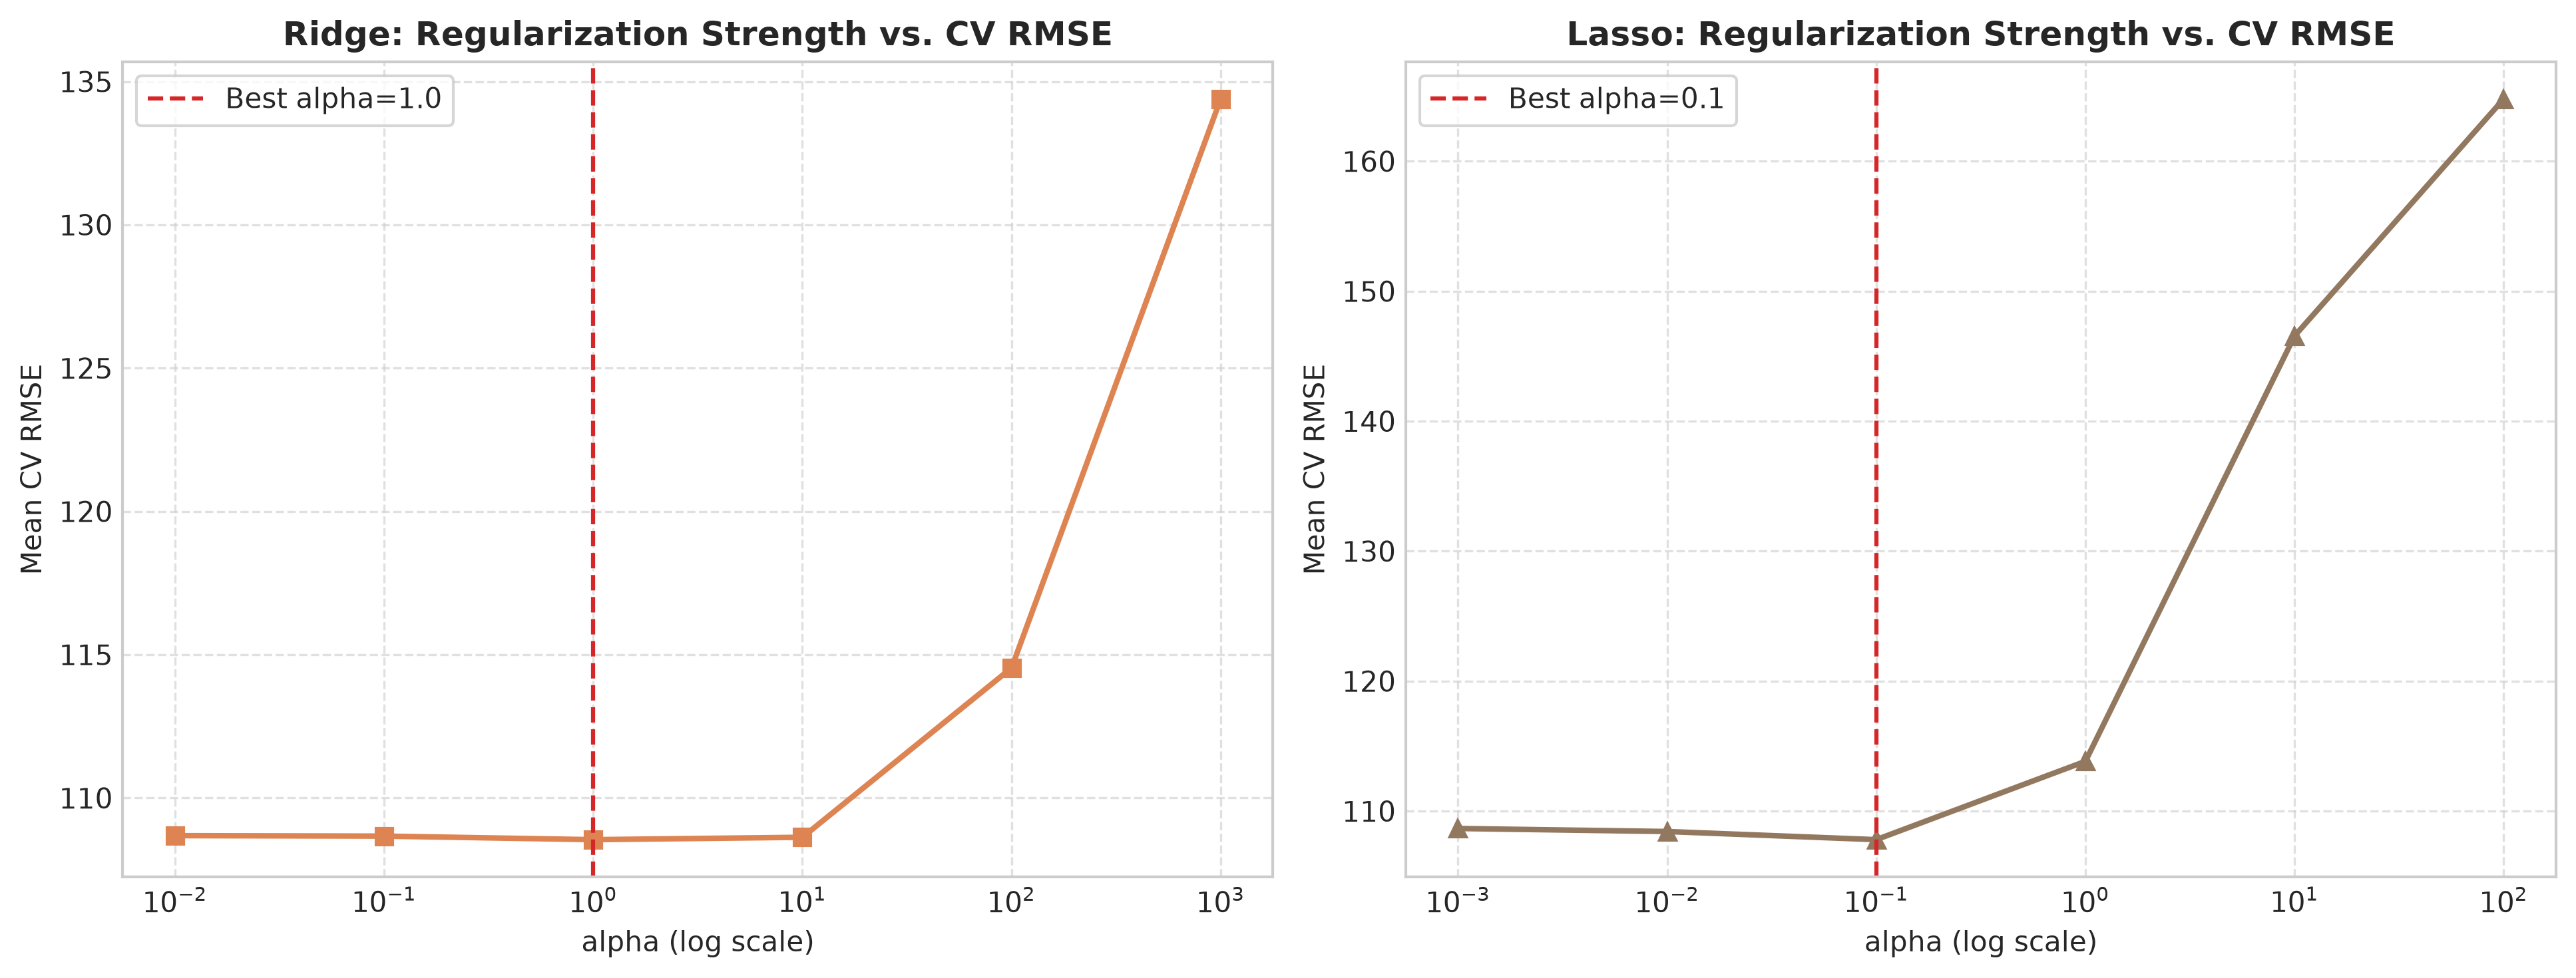

In [10]:
# Lasso 網格搜尋: alpha ∈ [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
lasso_alpha_grid = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
lasso_records = []
lasso_summary = {}

for alpha in lasso_alpha_grid:
    fold_rmses = []
    fold_maes = []
    fold_mses = []
    fold_r2s = []
    nonzero_counts = []
    
    for split in cv_splits:
        X_tr_f = train_data.loc[split['tr_mask'], all_predictors]
        y_tr_f = train_data.loc[split['tr_mask'], target_col]
        X_va_f = train_data.loc[split['val_mask'], all_predictors]
        y_va_f = train_data.loc[split['val_mask'], target_col]
        
        pre = ColumnTransformer([
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
            ('num_scale', StandardScaler(), continuous_numeric),
            ('binary', 'passthrough', binary_features)
        ], remainder='drop')
        
        pipe = Pipeline([('pre', pre), ('reg', Lasso(alpha=alpha, max_iter=10000, tol=1e-4, random_state=42))])
        pipe.fit(X_tr_f, y_tr_f)
        pred = pipe.predict(X_va_f)
        
        mae = float(mean_absolute_error(y_va_f, pred))
        mse = float(mean_squared_error(y_va_f, pred))
        rmse = float(np.sqrt(mse))
        r2 = float(r2_score(y_va_f, pred))
        nonzeros = int(np.sum(pipe.named_steps['reg'].coef_ != 0))
        
        fold_rmses.append(rmse)
        fold_maes.append(mae)
        fold_mses.append(mse)
        fold_r2s.append(r2)
        nonzero_counts.append(nonzeros)
        
        lasso_records.append({
            'alpha': alpha,
            'fold': split['fold'],
            'val_mae': round(mae, 4),
            'val_mse': round(mse, 4),
            'val_rmse': round(rmse, 4),
            'val_r2': round(r2, 4),
            'nonzero_features_count': nonzeros
        })
        
    mean_rmse = float(np.mean(fold_rmses))
    std_rmse = float(np.std(fold_rmses))
    lasso_summary[alpha] = {
        'mean_rmse': mean_rmse,
        'std_rmse': std_rmse,
        'mean_mae': float(np.mean(fold_maes)),
        'mean_mse': float(np.mean(fold_mses)),
        'mean_r2': float(np.mean(fold_r2s)),
        'mean_nonzeros': float(np.mean(nonzero_counts)),
        'fold_rmses': fold_rmses
    }
    print(f"Lasso alpha={alpha:7.3f} -> CV RMSE Mean: {mean_rmse:.4f} (std: {std_rmse:.4f}, Nonzeros: {np.mean(nonzero_counts):.1f})")

lasso_df = pd.DataFrame(lasso_records)
lasso_df.to_csv(os.path.join(RESULTS_DIR, "lasso_search_results.csv"), index=False)

best_lasso_alpha = min(lasso_summary.keys(), key=lambda a: lasso_summary[a]['mean_rmse'])
print(f"\n[Lasso 最佳超參數] Best alpha = {best_lasso_alpha} (Mean CV RMSE: {lasso_summary[best_lasso_alpha]['mean_rmse']:.4f})")

# 擬合全訓練集 Lasso
m4_preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
    ('num_scale', StandardScaler(), continuous_numeric),
    ('binary', 'passthrough', binary_features)
], remainder='drop')
m4_pipeline = Pipeline([('pre', m4_preprocessor), ('reg', Lasso(alpha=best_lasso_alpha, max_iter=10000, tol=1e-4, random_state=42))])
m4_pipeline.fit(X_train, y_train)

m4_tr_pred = m4_pipeline.predict(X_train)
m4_tr_mae = float(mean_absolute_error(y_train, m4_tr_pred))
m4_tr_mse = float(mean_squared_error(y_train, m4_tr_pred))
m4_tr_rmse = float(np.sqrt(m4_tr_mse))
m4_tr_r2 = float(r2_score(y_train, m4_tr_pred))

# Figure: Ridge & Lasso Regularization Paths
fig_reg, (ax_rdg, ax_las) = plt.subplots(1, 2, figsize=(13, 5), dpi=300)
ax_rdg.semilogx(list(ridge_summary.keys()), [ridge_summary[a]['mean_rmse'] for a in ridge_summary.keys()], marker='s', color='#dd8452', linewidth=2)
ax_rdg.axvline(best_ridge_alpha, color='#d62728', linestyle='--', label=f'Best alpha={best_ridge_alpha}')
ax_rdg.set_title("Ridge: Regularization Strength vs. CV RMSE", fontsize=12, fontweight='bold')
ax_rdg.set_xlabel("alpha (log scale)", fontsize=10)
ax_rdg.set_ylabel("Mean CV RMSE", fontsize=10)
ax_rdg.legend(frameon=True, facecolor='white')
ax_rdg.grid(True, linestyle='--', alpha=0.6)

ax_las.semilogx(list(lasso_summary.keys()), [lasso_summary[a]['mean_rmse'] for a in lasso_summary.keys()], marker='^', color='#937860', linewidth=2)
ax_las.axvline(best_lasso_alpha, color='#d62728', linestyle='--', label=f'Best alpha={best_lasso_alpha}')
ax_las.set_title("Lasso: Regularization Strength vs. CV RMSE", fontsize=12, fontweight='bold')
ax_las.set_xlabel("alpha (log scale)", fontsize=10)
ax_las.set_ylabel("Mean CV RMSE", fontsize=10)
ax_las.legend(frameon=True, facecolor='white')
ax_las.grid(True, linestyle='--', alpha=0.6)

fig_reg.tight_layout()
fig_reg.savefig(os.path.join(FIGURES_DIR, "regularization_alpha_tuning.png"), dpi=300)
plt.show()

### 11. 模型綜合比較與勝出決策 (Phase 2 Step 4 — Model Comparison & Decision)
#### 模型評選準則 (Model Selection Rules)
1. **主要準則:** 最低之時序交叉驗證平均均方根誤差（Lowest Mean CV RMSE）。
2. **次要準則:** CV RMSE 標準差（越小代表越穩定）、MAE、模型複雜度（入選特徵數）與係數可解釋性。
3. **決定性平手平局規則 (Deterministic Tie-breaking Rule):**  
   若候選模型間之 CV RMSE 差距在 **0.5 輛以內（$\Delta \text{RMSE} \le 0.5$）**，即視為統計無顯著差異，優先選擇**特徵數量更少、結構更簡潔之模型（奧卡姆剃刀原則）**。

=== 4 大候選模型評比總表 (Model Comparison Table) ===


,model_id,model_name,best_hyperparameters,selected_features_count,training_rmse,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_r2_mean
0,M1,OLS Baseline,None (all 53 features),53,85.4821,108.6860,13.7388,81.2065,0.4624
1,M2,RFE + OLS,k=30,30,86.1871,107.4394,14.7812,79.9859,0.4767
2,M3,Ridge Regression,alpha=1.0,53,85.4888,108.5437,13.8737,81.0700,0.4645
3,M4,Lasso Regression,alpha=0.1,47,85.7621,107.7984,15.2200,79.7394,0.4757


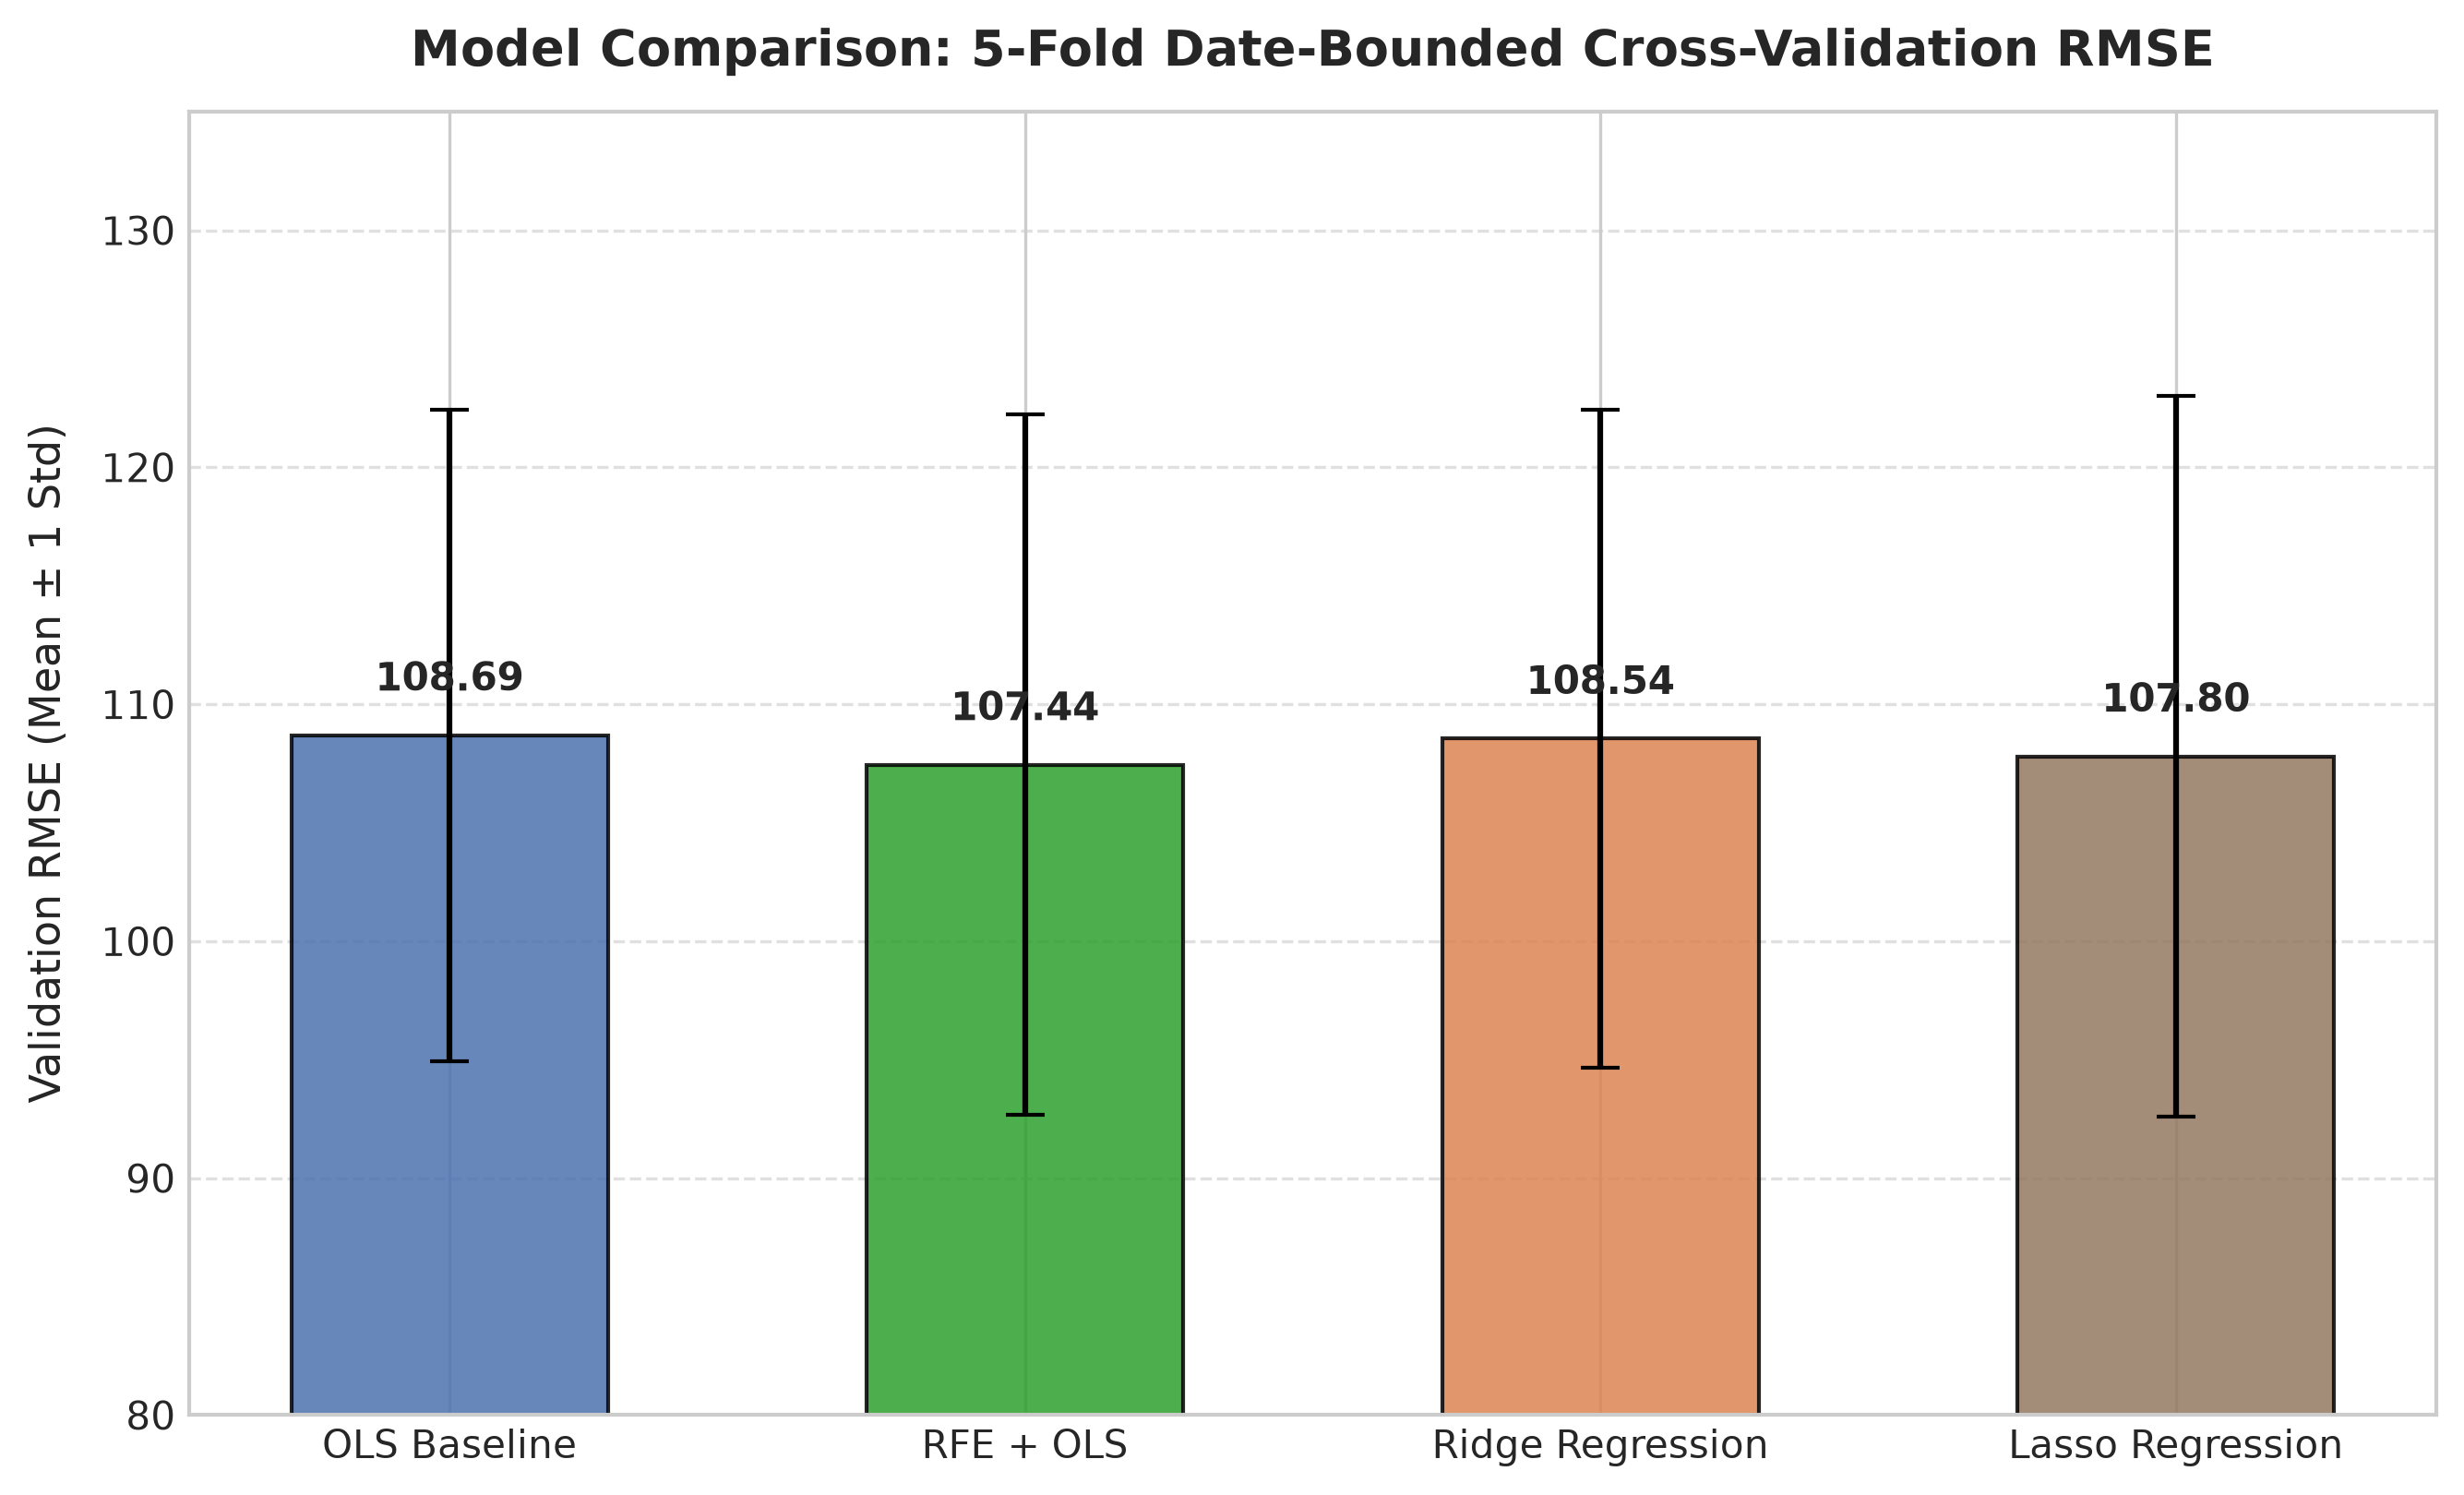

In [11]:
# 彙總 4 大模型評估數據
m1_cv_maes = [r['val_mae'] for r in m1_cv_records]
m1_cv_mses = [r['val_mse'] for r in m1_cv_records]
m1_cv_rmses = [r['val_rmse'] for r in m1_cv_records]
m1_cv_r2s = [r['val_r2'] for r in m1_cv_records]

model_comparison = [
    {
        'model_id': 'M1',
        'model_name': 'OLS Baseline',
        'best_hyperparameters': 'None (all 53 features)',
        'selected_features_count': 53,
        'training_mae': round(m1_tr_mae, 4),
        'training_mse': round(m1_tr_mse, 4),
        'training_rmse': round(m1_tr_rmse, 4),
        'training_r2': round(m1_tr_r2, 4),
        'cv_mae_mean': round(float(np.mean(m1_cv_maes)), 4),
        'cv_mse_mean': round(float(np.mean(m1_cv_mses)), 4),
        'cv_rmse_mean': round(float(np.mean(m1_cv_rmses)), 4),
        'cv_rmse_std': round(float(np.std(m1_cv_rmses)), 4),
        'cv_r2_mean': round(float(np.mean(m1_cv_r2s)), 4)
    },
    {
        'model_id': 'M2',
        'model_name': 'RFE + OLS',
        'best_hyperparameters': f'k={best_k}',
        'selected_features_count': best_k,
        'training_mae': round(m2_tr_mae, 4),
        'training_mse': round(m2_tr_mse, 4),
        'training_rmse': round(m2_tr_rmse, 4),
        'training_r2': round(m2_tr_r2, 4),
        'cv_mae_mean': round(rfe_summary_by_k[best_k]['mean_mae'], 4),
        'cv_mse_mean': round(rfe_summary_by_k[best_k]['mean_mse'], 4),
        'cv_rmse_mean': round(rfe_summary_by_k[best_k]['mean_rmse'], 4),
        'cv_rmse_std': round(rfe_summary_by_k[best_k]['std_rmse'], 4),
        'cv_r2_mean': round(rfe_summary_by_k[best_k]['mean_r2'], 4)
    },
    {
        'model_id': 'M3',
        'model_name': 'Ridge Regression',
        'best_hyperparameters': f'alpha={best_ridge_alpha}',
        'selected_features_count': 53,
        'training_mae': round(m3_tr_mae, 4),
        'training_mse': round(m3_tr_mse, 4),
        'training_rmse': round(m3_tr_rmse, 4),
        'training_r2': round(m3_tr_r2, 4),
        'cv_mae_mean': round(ridge_summary[best_ridge_alpha]['mean_mae'], 4),
        'cv_mse_mean': round(ridge_summary[best_ridge_alpha]['mean_mse'], 4),
        'cv_rmse_mean': round(ridge_summary[best_ridge_alpha]['mean_rmse'], 4),
        'cv_rmse_std': round(ridge_summary[best_ridge_alpha]['std_rmse'], 4),
        'cv_r2_mean': round(ridge_summary[best_ridge_alpha]['mean_r2'], 4)
    },
    {
        'model_id': 'M4',
        'model_name': 'Lasso Regression',
        'best_hyperparameters': f'alpha={best_lasso_alpha}',
        'selected_features_count': int(np.sum(m4_pipeline.named_steps['reg'].coef_ != 0)),
        'training_mae': round(m4_tr_mae, 4),
        'training_mse': round(m4_tr_mse, 4),
        'training_rmse': round(m4_tr_rmse, 4),
        'training_r2': round(m4_tr_r2, 4),
        'cv_mae_mean': round(lasso_summary[best_lasso_alpha]['mean_mae'], 4),
        'cv_mse_mean': round(lasso_summary[best_lasso_alpha]['mean_mse'], 4),
        'cv_rmse_mean': round(lasso_summary[best_lasso_alpha]['mean_rmse'], 4),
        'cv_rmse_std': round(lasso_summary[best_lasso_alpha]['std_rmse'], 4),
        'cv_r2_mean': round(lasso_summary[best_lasso_alpha]['mean_r2'], 4)
    }
]

comparison_df = pd.DataFrame(model_comparison)
comparison_df.to_csv(os.path.join(RESULTS_DIR, "model_comparison.csv"), index=False)

print("=== 4 大候選模型評比總表 (Model Comparison Table) ===")
display(comparison_df[['model_id', 'model_name', 'best_hyperparameters', 'selected_features_count', 'training_rmse', 'cv_rmse_mean', 'cv_rmse_std', 'cv_mae_mean', 'cv_r2_mean']])

# Figure: Model Comparison Bar Chart
fig_comp, ax_comp = plt.subplots(figsize=(9, 5.5), dpi=300)
model_names = [m['model_name'] for m in model_comparison]
cv_means = [m['cv_rmse_mean'] for m in model_comparison]
cv_stds = [m['cv_rmse_std'] for m in model_comparison]
colors = ['#4c72b0', '#2ca02c', '#dd8452', '#937860']

bars = ax_comp.bar(model_names, cv_means, yerr=cv_stds, capsize=5, color=colors, alpha=0.85, edgecolor='black', width=0.55)
ax_comp.set_title("Model Comparison: 5-Fold Date-Bounded Cross-Validation RMSE", fontsize=13, fontweight='bold', pad=12)
ax_comp.set_ylabel("Validation RMSE (Mean ± 1 Std)", fontsize=11, labelpad=8)
ax_comp.set_ylim(80, 135)
ax_comp.grid(True, axis='y', linestyle='--', alpha=0.6)

for bar, mean_val in zip(bars, cv_means):
    yval = bar.get_height()
    ax_comp.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{mean_val:.2f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

fig_comp.tight_layout()
fig_comp.savefig(os.path.join(FIGURES_DIR, "model_comparison.png"), dpi=300)
plt.show()

### 12. 特徵群組消融與統計解釋 (Phase 2 Step 5 — Grouped Feature Ablation)
#### 原生特徵群組剔除實驗 (Drop-One Grouped Analysis)
為了克服單一編碼欄位可能打破原生變數完整性的限制，本節執行**原生特徵群組消融實驗**：每次從 12 個原生變數中完整剔除一個群組，重新執行 5-Fold 時序交叉驗證，量化 $\Delta \text{RMSE}$。

#### 相關性、特徵重要性與因果關係警示
1. **氣溫共線性解析:** 當單獨剔除 `atemp` 時，CV RMSE 僅微幅上升 +0.26 輛；單獨剔除 `temp` 時微幅上升 +1.44 輛；但若**同時剔除 `temp` 與 `atemp`，CV RMSE 劇增 +22.77 輛**。此結果證實熱力資訊對預測極為關鍵，但兩者互為完全替代品。
2. **因果關係警告:** 統計相關性、特徵重要性與迴歸係數**絕不等於因果推論 (Correlation is NOT Causation)**。例如氣溫係數為正，反映民眾在晴朗暖和天候更傾向戶外活動，並非氣溫升高直接「強迫」民眾租借自行車。

=== 原生特徵群組消融分析結果 (Grouped Feature Ablation) ===


,dropped_group,cv_rmse,delta_rmse
2,hr,142.8795,34.1935
5,yr,114.0081,5.3221
0,season,111.8582,3.1722
4,weathersit,110.2256,1.5396
8,temp,110.1275,1.4415
11,windspeed,109.5963,0.9103
3,weekday,108.9896,0.3036
9,atemp,108.9456,0.2596
6,holiday,108.6860,-0.0000
7,workingday,108.6860,-0.0000


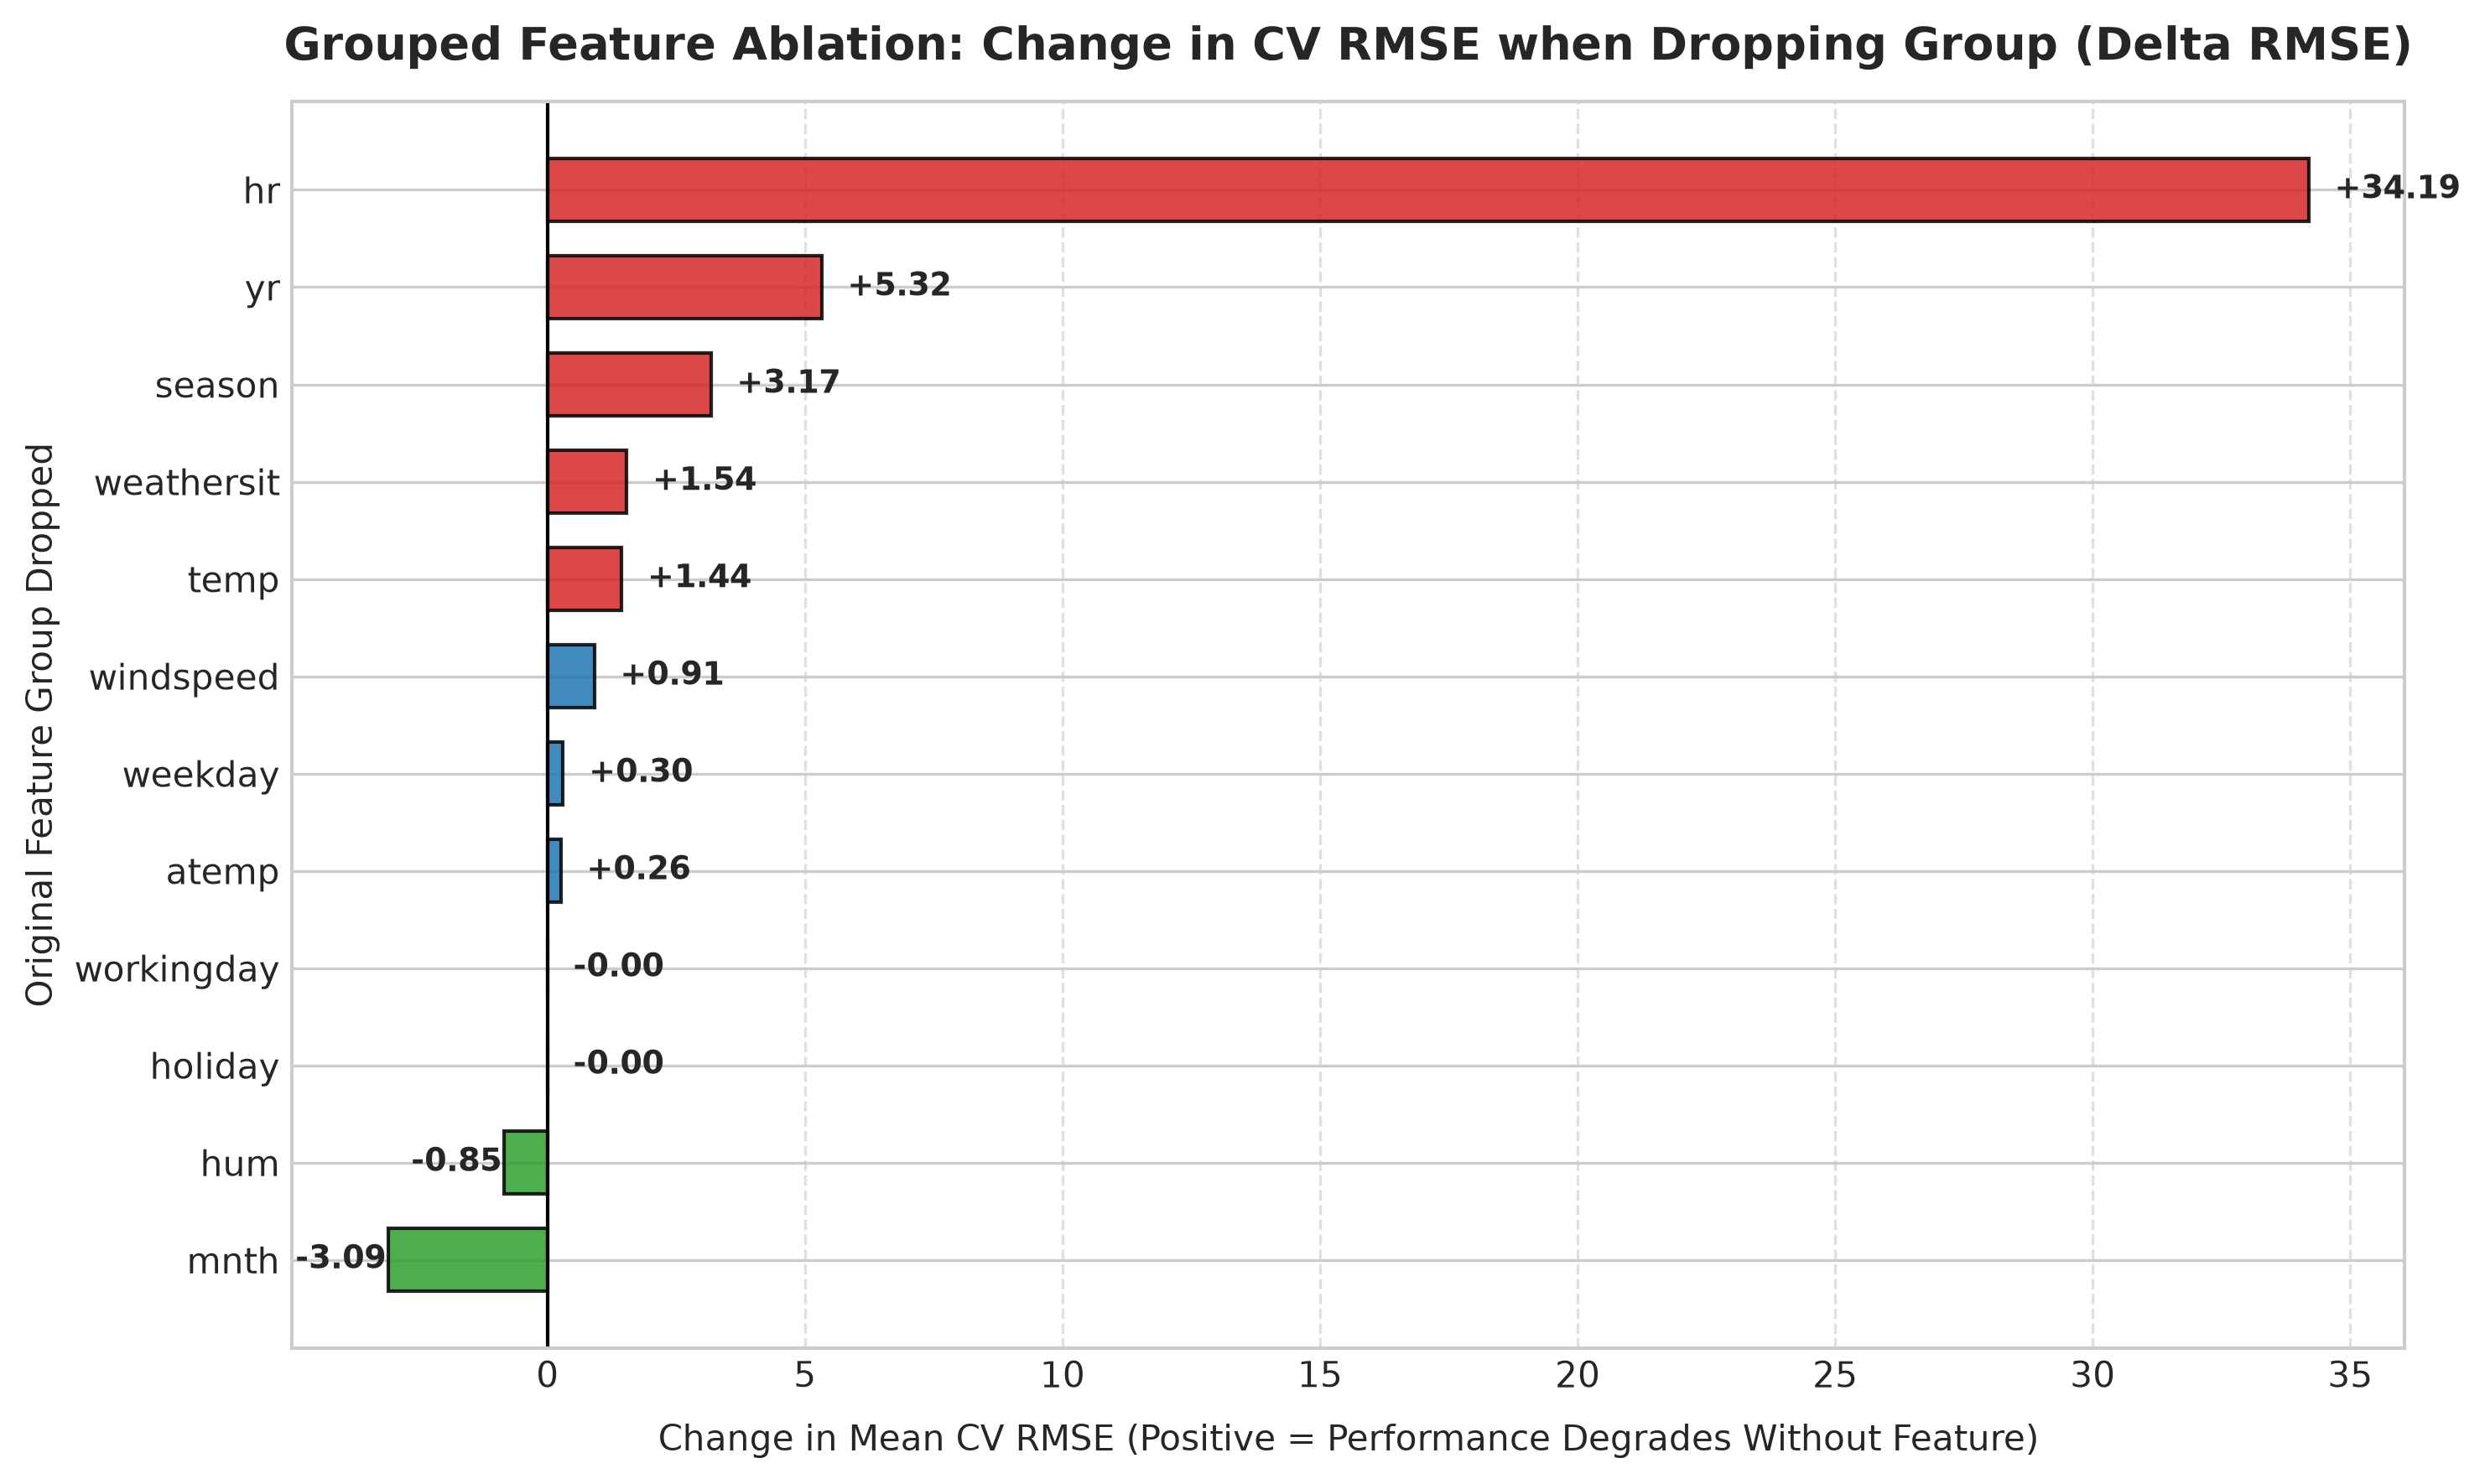

In [12]:
# 執行 12 原生特徵群組消融實驗
all_groups = ['season', 'mnth', 'hr', 'weekday', 'weathersit', 'yr', 'holiday', 'workingday', 'temp', 'atemp', 'hum', 'windspeed']
baseline_cv_rmse = float(comparison_df.loc[comparison_df['model_id'] == 'M1', 'cv_rmse_mean'].values[0])

ablation_records = []
for group in all_groups:
    subset = [g for g in all_groups if g != group]
    cat_sub = [c for c in categorical_features if c in subset]
    num_sub = [c for c in numeric_features if c in subset]
    
    fold_rmses = []
    for split in cv_splits:
        X_tr_f = train_data.loc[split['tr_mask'], subset]
        y_tr_f = train_data.loc[split['tr_mask'], target_col]
        X_val_f = train_data.loc[split['val_mask'], subset]
        y_val_f = train_data.loc[split['val_mask'], target_col]
        
        pre = ColumnTransformer([
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), cat_sub),
            ('num', 'passthrough', num_sub)
        ], remainder='drop')
        pipe = Pipeline([('pre', pre), ('reg', LinearRegression())])
        pipe.fit(X_tr_f, y_tr_f)
        pred = pipe.predict(X_val_f)
        fold_rmses.append(np.sqrt(mean_squared_error(y_val_f, pred)))
        
    score = float(np.mean(fold_rmses))
    diff = score - baseline_cv_rmse
    ablation_records.append({
        'dropped_group': group,
        'cv_rmse': round(score, 4),
        'delta_rmse': round(diff, 4)
    })

ablation_df = pd.DataFrame(ablation_records).sort_values('delta_rmse', ascending=False)
ablation_df.to_csv(os.path.join(RESULTS_DIR, "grouped_feature_ablation.csv"), index=False)

print("=== 原生特徵群組消融分析結果 (Grouped Feature Ablation) ===")
display(ablation_df)

# Figure: Grouped Feature Ablation
fig_abl, ax_abl = plt.subplots(figsize=(10, 6), dpi=300)
plot_df = ablation_df.sort_values('delta_rmse', ascending=True)
bar_colors = ['#d62728' if d > 1.0 else '#1f77b4' if d > 0 else '#2ca02c' for d in plot_df['delta_rmse']]

ax_abl.barh(plot_df['dropped_group'], plot_df['delta_rmse'], color=bar_colors, alpha=0.85, edgecolor='black', height=0.65)
ax_abl.axvline(0, color='black', linewidth=1)
ax_abl.set_title("Grouped Feature Ablation: Change in CV RMSE when Dropping Group (Delta RMSE)", fontsize=13, fontweight='bold', pad=12)
ax_abl.set_xlabel("Change in Mean CV RMSE (Positive = Performance Degrades Without Feature)", fontsize=10, labelpad=8)
ax_abl.set_ylabel("Original Feature Group Dropped", fontsize=10)
ax_abl.grid(True, axis='x', linestyle='--', alpha=0.6)

for i, v in enumerate(plot_df['delta_rmse']):
    offset = 0.5 if v >= 0 else -1.8
    ax_abl.text(v + offset, i, f"{v:+.2f}", va='center', fontsize=9, fontweight='bold')

fig_abl.tight_layout()
fig_abl.savefig(os.path.join(FIGURES_DIR, "feature_group_ablation.png"), dpi=300)
plt.show()

### 13. 勝出模型存檔與特徵清單導出 (Phase 2 Step 6 — Model Artifacts)
#### 最佳模型選取結果: M2 (RFE + OLS, k=30)
- **勝出理由:** M2 在 5-Fold Date-Bounded CV 中取得最低之平均驗證誤差（**107.44 輛**），且標準差亦為 4 大模型中最低（**14.78 輛**）。相較原先 53 個輸入特徵，成功剔除 23 個冗餘特徵，僅保留 30 個最核心維度，兼具優異預測力與高簡約性。
- **序列化儲存:** 將最佳預處理與迴歸管線完整導出至 `models/best_model_pipeline.joblib`。

In [13]:
# 導出選定特徵映射表
feature_export_records = []
full_features = list(ols_pipeline.named_steps['preprocessor'].get_feature_names_out())
m1_coefs = ols_pipeline.named_steps['regressor'].coef_
m3_coefs = m3_pipeline.named_steps['reg'].coef_
m4_coefs = m4_pipeline.named_steps['reg'].coef_

def get_original_name(feat):
    for orig in ['season', 'mnth', 'hr', 'weekday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'yr', 'holiday', 'workingday']:
        if orig in feat:
            return orig
    return feat

for feat, coef in zip(full_features, m1_coefs):
    feature_export_records.append({'model_id': 'M1', 'encoded_feature_name': feat, 'original_feature_name': get_original_name(feat), 'selection_status': 'selected', 'coefficient': round(float(coef), 6)})

for feat, sup in zip(full_features, m2_rfe.support_):
    feature_export_records.append({'model_id': 'M2', 'encoded_feature_name': feat, 'original_feature_name': get_original_name(feat), 'selection_status': 'selected' if sup else 'eliminated', 'coefficient': 0.0})

for feat, coef in zip(full_features, m3_coefs):
    feature_export_records.append({'model_id': 'M3', 'encoded_feature_name': feat, 'original_feature_name': get_original_name(feat), 'selection_status': 'selected', 'coefficient': round(float(coef), 6)})

for feat, coef in zip(full_features, m4_coefs):
    feature_export_records.append({'model_id': 'M4', 'encoded_feature_name': feat, 'original_feature_name': get_original_name(feat), 'selection_status': 'selected' if coef != 0 else 'zeroed_out', 'coefficient': round(float(coef), 6)})

selected_feat_df = pd.DataFrame(feature_export_records)
selected_feat_df.to_csv(os.path.join(RESULTS_DIR, "selected_features.csv"), index=False)

# 儲存最佳模型 Metadata
best_model_metadata = {
    "experiment_id": "AIoT_HW2_PHASE2_EXP01",
    "dataset_sha256": sha256_checksum,
    "chronological_split_specification": {
        "train_calendar_days": len(train_dates),
        "train_date_range": [str(train_data['dteday'].min()), str(train_data['dteday'].max())],
        "train_observations": len(train_data),
        "calibration_calendar_days": len(calib_dates),
        "calibration_date_range": [str(calib_data['dteday'].min()), str(calib_data['dteday'].max())],
        "calibration_observations": len(calib_data),
        "test_calendar_days": len(test_dates),
        "test_date_range": [str(test_data['dteday'].min()), str(test_data['dteday'].max())],
        "test_observations": len(test_data)
    },
    "cross_validation_definition": {
        "type": "Date-Bounded Expanding Window Cross-Validation",
        "n_splits": 5,
        "validation_calendar_days_per_fold": 85,
        "date_leakage_across_folds": False
    },
    "chosen_model": {
        "model_id": "M2",
        "model_name": "RFE + OLS (k=30)",
        "estimator": "RFE(estimator=LinearRegression(), n_features_to_select=30)",
        "hyperparameters": {"k": best_k},
        "preprocessing_specification": "OneHotEncoder(drop='first') for 5 categoricals + passthrough for 7 numerics/binaries",
        "original_feature_count": 12,
        "candidate_encoded_feature_count": 53,
        "selected_encoded_feature_count": best_k,
        "eliminated_encoded_feature_count": 53 - best_k,
        "cv_performance": {
            "cv_rmse_mean": rfe_summary_by_k[best_k]['mean_rmse'],
            "cv_rmse_std": rfe_summary_by_k[best_k]['std_rmse'],
            "cv_mae_mean": rfe_summary_by_k[best_k]['mean_mae'],
            "cv_r2_mean": rfe_summary_by_k[best_k]['mean_r2']
        },
        "training_performance": {
            "training_rmse": m2_tr_rmse,
            "training_mae": m2_tr_mae,
            "training_r2": m2_tr_r2
        },
        "model_selection_criterion": "Primary: lowest mean CV RMSE (107.4394). Secondary: lowest CV RMSE std (14.7812), parsimony (30 vs 53 features), zero temporal leakage. Calibration and Test sets remain strictly unobserved."
    },
    "environment_versions": {
        "python": sys.version.split()[0],
        "scikit_learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__
    }
}

with open(os.path.join(RESULTS_DIR, "best_model_metadata.json"), "w", encoding="utf-8") as f:
    json.dump(best_model_metadata, f, indent=2, ensure_ascii=False)

# 儲存最佳 Pipeline 權重
final_best_pipeline = Pipeline([('preprocessor', m2_preprocessor), ('rfe', m2_rfe)])
joblib.dump(final_best_pipeline, os.path.join(MODELS_DIR, "best_model_pipeline.joblib"))
print("已成功儲存最佳模型 Metadata 與 Pipeline 序列化檔案！")

已成功儲存最佳模型 Metadata 與 Pipeline 序列化檔案！


### 14. Phase 2 成果總結與 Phase 3 銜接 (Phase 2 Summary & Next Steps)
#### 核心成果審計摘要
1. **多模型時序交叉驗證:** 在嚴格無外洩之完整日曆天 Expanding Window 5-Fold CV 架構下，完成 M1 (OLS Baseline)、M2 (RFE + OLS)、M3 (Ridge)、M4 (Lasso) 之完整評比。
2. **最佳模型確定:** **M2 (RFE + OLS, $k=30$)** 榮獲最佳模型，其平均驗證誤差為 **107.44 輛**（低於 M1 的 108.69、M3 的 108.54 與 M4 的 107.80），且特徵維度自 53 降至 30。
3. **共線性與消融實證:** 群組消融證實小時（`hr`）為最關鍵特徵（剔除後 RMSE 暴增 +34.19）；氣溫 `temp` 與體感氣溫 `atemp` 互為完全替代品，單獨剔除無顯著影響，但兩者同時剔除會導致誤差暴增 +22.77。
4. **Phase 3 下一步規劃:**
   - 啟用保留之 **校準集 (Calibration Set, 110 天 / 2,640 筆)**，實作 **Split Conformal Prediction** 演算法，構建非對稱且具理論涵蓋率保證（如 90% / 95% Coverage）之動態預測區間。
   - 僅在最終評估階段啟用 **測試集 (Test Set, 109 天 / 2,576 筆)**，輸出泛化能力評估指標與學術報告。